# 🏥 HealthWise Insurance — Smart Premium Engine
### End-to-End Machine Learning Lab · MAIB

**Student:** _Your Name_ &nbsp;|&nbsp; **Roll No:** _Your Roll No_

HealthWise charges everyone one flat price. Low-risk customers are overcharged and leave; high-risk customers are undercharged and create losses. This notebook builds a **two-stage Smart Premium Engine**:

1. **Stage 1 — Classify** each customer into a risk tier (Low / Medium / High).
2. **Stage 2 — Predict** the annual charge with a regression model trained **only on that tier**.
3. **Price** it with an explicit premium formula (expected charge + loadings).

| Part | What is inside |
|---|---|
| **A** Foundations | load, clean (duplicates, smart BMI imputation), EDA, feature audit, hypothesis tests, VIF, encoding, feature engineering, Lasso audit |
| **B** Stage 1 | **Naive Bayes** (Gaussian + Categorical), **KNN**, **Decision Tree (Gini & Entropy)**, Logistic Regression · raw vs engineered features · a hand-readable risk **scorecard** |
| **C** Stage 2 | global baseline, simple vs multiple regression, per-tier engine, realistic end-to-end test, Ridge/Lasso tuning, model ladder |
| **Extensions** | **Clustering** (K-Means + hierarchical) · **Dimensionality reduction** (PCA + LDA) · **The Premium Formula** + fairness check vs flat pricing |
| **D** Board memo | the recommendation |
| **E** Deployment | saved `healthwise_model.joblib`, prediction function, live ipywidgets GUI, Streamlit app (`app.py`), unseen-customer scoring |
| **Bonus** | error propagation & PCA reasoning |

One fixed `RANDOM_STATE = 42` is used everywhere.

## ⚙️ Setup

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, GridSearchCV,
                                     cross_val_score, cross_val_predict)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression, RidgeCV, LassoCV
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, f1_score,
                             confusion_matrix, classification_report, silhouette_score, adjusted_rand_score)
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from IPython.display import display, Markdown

pd.set_option('display.max_columns', None); pd.set_option('display.width', 170)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

TIERS = ['Low', 'Medium', 'High']
TIER_COLORS = {'Low': '#2a9d8f', 'Medium': '#e9c46a', 'High': '#e76f51'}
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))

# PART A — Foundations (Understand, Clean & Select)

## Task A1 — Load and Inspect

In [2]:
df = pd.read_csv('healthwise.csv')
print("Shape:", df.shape)
display(df.head())
df.info()
display(df.describe(include='all').T)
print("Numeric columns    :", df.select_dtypes(include='number').columns.tolist())
print("Categorical columns:", df.select_dtypes(exclude='number').columns.tolist())

Shape: (1203, 17)


,customer_id,age,sex,bmi,weight_kg,children,smoker,region,exercise_freq,date_of_birth,favorite_color,zodiac_sign,lucky_number,preferred_contact,marketing_opt_in,annual_charge,risk_tier
0,HW1000,56,female,29.7,85.6,1,no,south,3.0,1970-05-14,purple,Leo,54,sms,yes,14924.08,Medium
1,HW1001,46,female,24.1,69.9,4,yes,west,5.0,1980-09-17,red,Virgo,81,phone,yes,45450.69,High
2,HW1002,32,female,34.4,100.1,0,yes,north,3.0,1994-05-07,yellow,Libra,7,sms,yes,43874.19,High
3,HW1003,60,female,27.0,78.7,0,yes,north,4.0,1966-11-22,blue,Capricorn,17,sms,no,48107.39,High
4,HW1004,25,male,31.3,90.0,1,no,north,4.0,2001-06-12,blue,Pisces,50,sms,yes,13745.61,Medium


<class 'pandas.DataFrame'>
RangeIndex: 1203 entries, 0 to 1202
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        1203 non-null   str    
 1   age                1203 non-null   int64  
 2   sex                1203 non-null   str    
 3   bmi                1185 non-null   float64
 4   weight_kg          1203 non-null   float64
 5   children           1203 non-null   int64  
 6   smoker             1203 non-null   str    
 7   region             1203 non-null   str    
 8   exercise_freq      1185 non-null   float64
 9   date_of_birth      1203 non-null   str    
 10  favorite_color     1203 non-null   str    
 11  zodiac_sign        1203 non-null   str    
 12  lucky_number       1203 non-null   int64  
 13  preferred_contact  1203 non-null   str    
 14  marketing_opt_in   1203 non-null   str    
 15  annual_charge      1203 non-null   float64
 16  risk_tier          1203 non-null   

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,1203,1200,HW1005,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1203.0,NaN,NaN,NaN,41.139651,13.534406,18.0,29.0,42.0,53.0,64.0
sex,1203,2,male,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1185.0,NaN,NaN,NaN,27.865654,5.813073,16.0,23.7,28.0,31.8,44.4
weight_kg,1203.0,NaN,NaN,NaN,80.515794,16.841422,43.9,68.5,80.6,92.15,130.6
children,1203.0,NaN,NaN,NaN,1.985869,1.419721,0.0,1.0,2.0,3.0,4.0
smoker,1203,2,no,837,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1203,4,north,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
exercise_freq,1185.0,NaN,NaN,NaN,3.997468,1.234701,0.0,3.0,4.0,5.0,7.0
date_of_birth,1203,1154,1995-03-23,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Numeric columns    : ['age', 'bmi', 'weight_kg', 'children', 'exercise_freq', 'lucky_number', 'annual_charge']
Categorical columns: ['customer_id', 'sex', 'smoker', 'region', 'date_of_birth', 'favorite_color', 'zodiac_sign', 'preferred_contact', 'marketing_opt_in', 'risk_tier']


### ✍️ Reflection A1

1. **1,203 rows × 17 columns** (the brief says 16, but it lists 17 including both targets). One row = **one customer's annual policy record**.
2. **Numeric (7):** `age`, `bmi`, `weight_kg`, `children`, `exercise_freq`, `lucky_number`, `annual_charge` — `children` and `exercise_freq` are whole-number counts. **Categorical (10):** `customer_id`, `sex`, `smoker`, `region`, `date_of_birth` (really a date), `favorite_color`, `zodiac_sign`, `preferred_contact`, `marketing_opt_in`, `risk_tier`.
3. **Suspicious as cost predictors:** `customer_id` (a label), `favorite_color`, `zodiac_sign`, `lucky_number`, `preferred_contact`, `marketing_opt_in` (no medical link). **Suspicious as duplicates:** `date_of_birth` (same information as `age`) and `weight_kg` (overlaps `bmi`). The `describe()` also shows `customer_id` has only 1,200 unique values for 1,203 rows → duplicates exist.

## Task A2 — Clean the Data

In [3]:
print("Duplicate rows:", df.duplicated().sum())
display(df[df.duplicated(keep=False)].sort_values('customer_id'))
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after dropping duplicates:", len(df),
      "| duplicate customer_ids left:", df['customer_id'].duplicated().sum())
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

Duplicate rows: 3


,customer_id,age,sex,bmi,weight_kg,children,smoker,region,exercise_freq,date_of_birth,favorite_color,zodiac_sign,lucky_number,preferred_contact,marketing_opt_in,annual_charge,risk_tier
5,HW1005,38,male,22.5,65.8,2,no,south,5.0,1988-07-06,red,Libra,24,phone,no,7498.53,Low
1200,HW1005,38,male,22.5,65.8,2,no,south,5.0,1988-07-06,red,Libra,24,phone,no,7498.53,Low
6,HW1006,56,male,27.8,79.8,0,yes,south,5.0,1970-05-16,blue,Libra,2,sms,no,45206.27,High
1201,HW1006,56,male,27.8,79.8,0,yes,south,5.0,1970-05-16,blue,Libra,2,sms,no,45206.27,High
7,HW1007,36,male,40.0,116.9,4,yes,east,1.0,1990-10-05,yellow,Libra,99,email,no,55009.88,High
1202,HW1007,36,male,40.0,116.9,4,yes,east,1.0,1990-10-05,yellow,Libra,99,email,no,55009.88,High


Rows after dropping duplicates: 1200 | duplicate customer_ids left: 0

Missing values per column:
bmi              18
exercise_freq    18
dtype: int64


**YOUR CHOICE — imputation.** `bmi` and `weight_kg` are almost the same measurement (checked below, r ≈ 0.99), and `weight_kg` is never missing. So instead of giving every missing BMI the same median, I **predict BMI from weight** with a one-variable regression. `exercise_freq` is a small whole-number count (0–7), so the **median** (which equals the mode, 4) keeps it realistic.

In [4]:
known = df['bmi'].notna()
bmi_fit = LinearRegression().fit(df.loc[known, ['weight_kg']], df.loc[known, 'bmi'])
r2_bw = bmi_fit.score(df.loc[known, ['weight_kg']], df.loc[known, 'bmi'])
print(f"bmi ≈ {bmi_fit.intercept_:.3f} + {bmi_fit.coef_[0]:.4f} × weight_kg   (R² = {r2_bw:.3f})")

miss = df['bmi'].isna()
compare = pd.DataFrame({'weight_kg': df.loc[miss, 'weight_kg'],
                        'median_fill': df['bmi'].median(),
                        'regression_fill': bmi_fit.predict(df.loc[miss, ['weight_kg']]).round(1)})
display(compare.head(8))
print(f"bmi  → mean = {df['bmi'].mean():.2f}, median = {df['bmi'].median():.2f}, skew = {df['bmi'].skew():.2f}")

df.loc[miss, 'bmi'] = bmi_fit.predict(df.loc[miss, ['weight_kg']]).round(1)
df['exercise_freq'] = df['exercise_freq'].fillna(df['exercise_freq'].median())
print("Remaining missing:", df.isna().sum().sum())

bmi ≈ 0.359 + 0.3420 × weight_kg   (R² = 0.985)


,weight_kg,median_fill,regression_fill
63,88.4,28.0,30.6
199,101.6,28.0,35.1
266,66.2,28.0,23.0
314,92.5,28.0,32.0
448,84.3,28.0,29.2
488,96.4,28.0,33.3
513,68.8,28.0,23.9
536,94.7,28.0,32.7


bmi  → mean = 27.86, median = 28.00, skew = 0.11
Remaining missing: 0


In [5]:
# Sanity checks: impossible values, category typos, and "outliers"
display(df[['age','bmi','weight_kg','children','exercise_freq','lucky_number','annual_charge']].agg(['min','max']).T)
for c in ['sex','smoker','region','risk_tier']:
    print(f"{c:10} → {sorted(df[c].unique())}")
q1, q3 = df['annual_charge'].quantile([.25, .75]); upper = q3 + 1.5 * (q3 - q1)
out = df[df['annual_charge'] > upper]
print(f"\nIQR 'outliers' in annual_charge: {len(out)} rows above ${upper:,.0f}")
print("   their tiers:", out['risk_tier'].value_counts().to_dict(),
      f"| smokers among them: {(out['smoker']=='yes').mean():.0%}  → genuine high-cost customers, NOT errors (kept)")

,min,max
age,18.00,64.00
bmi,16.00,44.40
weight_kg,43.90,130.60
children,0.00,4.00
exercise_freq,0.00,7.00
lucky_number,1.00,99.00
annual_charge,5176.29,59200.37


sex        → ['female', 'male']
smoker     → ['no', 'yes']
region     → ['east', 'north', 'south', 'west']
risk_tier  → ['High', 'Low', 'Medium']

IQR 'outliers' in annual_charge: 265 rows above $34,081
   their tiers: {'High': 265} | smokers among them: 79%  → genuine high-cost customers, NOT errors (kept)


### ✍️ Reflection A2

1. **3 duplicate rows** removed (customers HW1005, HW1006, HW1007 each appeared twice, identical in every column) → 1,200 customers. Duplicates are dangerous because they (a) give those customers double weight, and (b) if one copy lands in training and the other in the test set, the model is tested on data it has already seen — the test score looks better than reality (**data leakage**).
2. `bmi` — **18 missing**, `exercise_freq` — **18 missing** (1.5% each). Nothing else.
3. **BMI:** I did *not* use a blind median. `bmi` and `weight_kg` correlate at 0.99 and `weight_kg` is never missing, so I predicted BMI from weight (R² = 0.985). The difference matters: the customer weighing 101.6 kg gets BMI **35.1** from the regression but **28.0** from the median — the median would have silently moved an obese person below the BMI-30 line that drives the risk tier. **Exercise:** a whole-number count 0–7, so the **median (4, also the mode)** keeps it a realistic value.
   *Why median beats mean for skewed data:* the mean is dragged toward extreme values, the median is not, so for a skewed column the median is closer to a "typical" customer. Here BMI is only mildly skewed (skew 0.11, mean 27.86 vs median 28.0) so both would be similar — but the regression is better than either.
   *Extra check:* the IQR rule flags **265 "outliers"** in `annual_charge`, but **all 265 are High-tier** (79% smokers). They are real expensive customers, not errors, so I kept them — deleting them would delete exactly the customers HealthWise is losing money on.

## Task A3 — Exploratory Data Analysis (EDA)

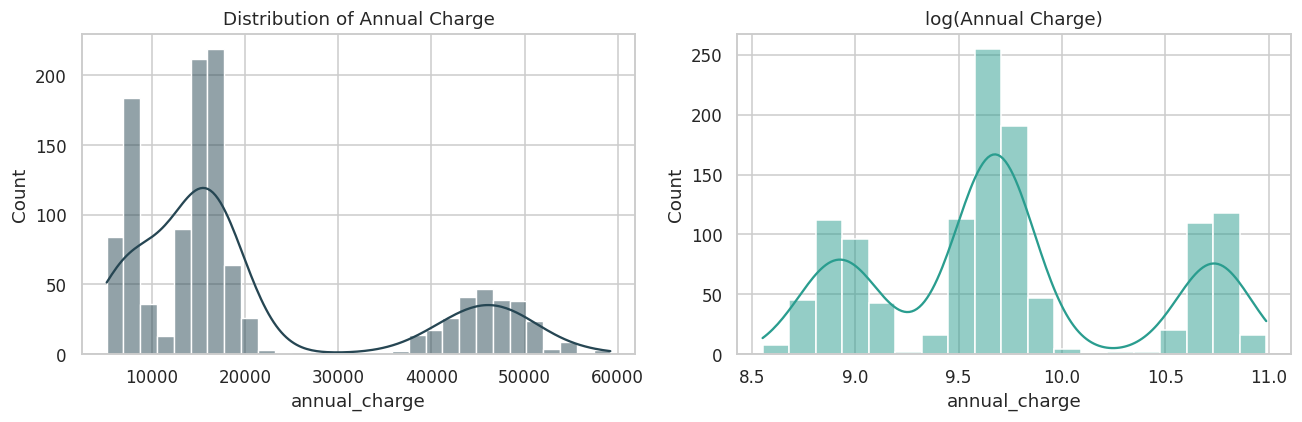

Skew of annual_charge     : 1.15
Skew of log(annual_charge): 0.38


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['annual_charge'], kde=True, ax=ax[0], color='#264653'); ax[0].set_title('Distribution of Annual Charge')
sns.histplot(np.log(df['annual_charge']), kde=True, ax=ax[1], color='#2a9d8f'); ax[1].set_title('log(Annual Charge)')
plt.tight_layout(); plt.show()
print("Skew of annual_charge     :", round(df['annual_charge'].skew(), 2))
print("Skew of log(annual_charge):", round(np.log(df['annual_charge']).skew(), 2))

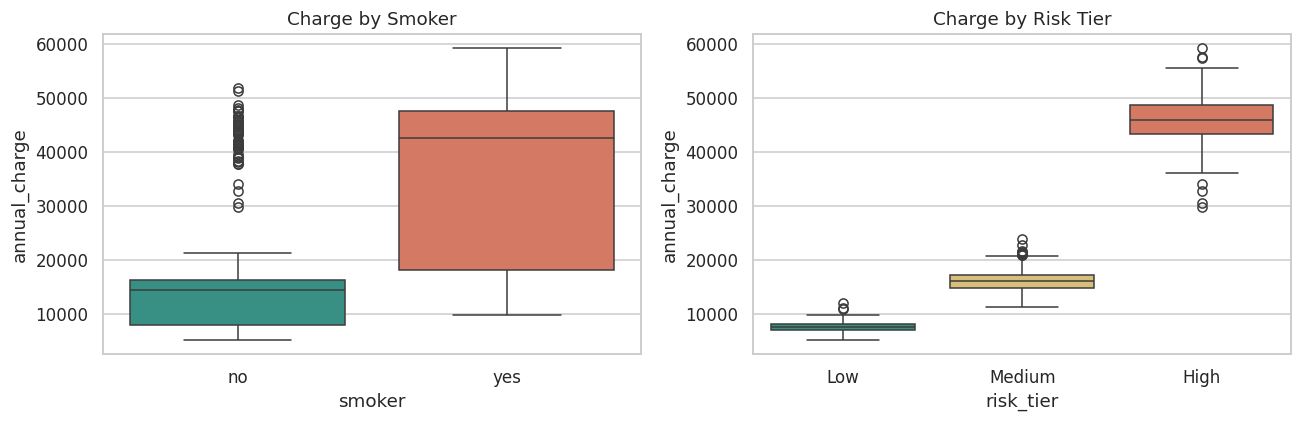

,mean,median,count
smoker,,,
no,14474.0,14379.0,836
yes,34511.0,42486.0,364


Smokers cost 2.38× non-smokers on average (+$20,037 per year)


,count,share
risk_tier,,
Low,307,0.256
Medium,625,0.521
High,268,0.223


,min,mean,max
risk_tier,,,
Low,5176.0,7592.0,11949.0
Medium,11302.0,16046.0,23775.0
High,29691.0,45904.0,59200.0


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='smoker', y='annual_charge', ax=ax[0], hue='smoker', palette=['#2a9d8f', '#e76f51'], legend=False)
ax[0].set_title('Charge by Smoker')
sns.boxplot(data=df, x='risk_tier', y='annual_charge', order=TIERS, hue='risk_tier', palette=TIER_COLORS, ax=ax[1], legend=False)
ax[1].set_title('Charge by Risk Tier')
plt.tight_layout(); plt.show()

m = df.groupby('smoker')['annual_charge'].agg(['mean', 'median', 'count']).round(0); display(m)
print(f"Smokers cost {m.loc['yes','mean']/m.loc['no','mean']:.2f}× non-smokers on average "
      f"(+${m.loc['yes','mean']-m.loc['no','mean']:,.0f} per year)")
vc = df['risk_tier'].value_counts().reindex(TIERS)
display(pd.DataFrame({'count': vc, 'share': (vc / len(df)).round(3)}))
display(df.groupby('risk_tier')['annual_charge'].agg(['min', 'mean', 'max']).reindex(TIERS).round(0))

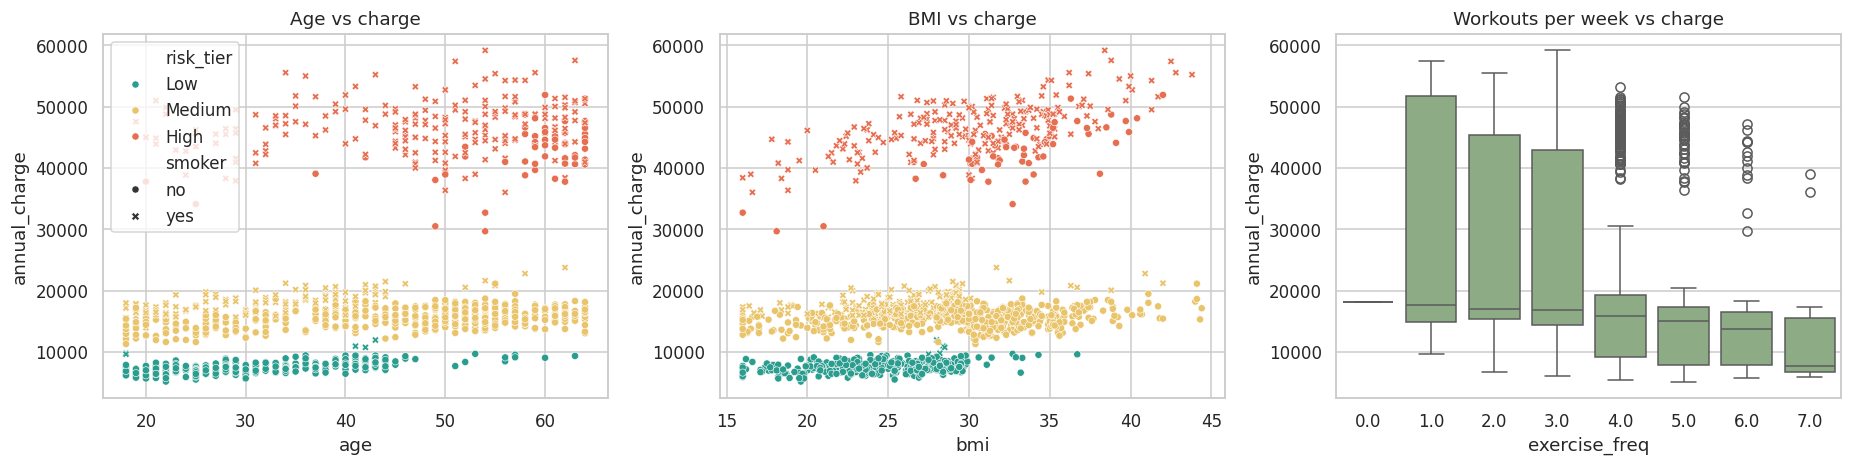

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
sns.scatterplot(data=df, x='age', y='annual_charge', hue='risk_tier', hue_order=TIERS, palette=TIER_COLORS,
                style='smoker', s=22, ax=ax[0]); ax[0].set_title('Age vs charge')
sns.scatterplot(data=df, x='bmi', y='annual_charge', hue='risk_tier', hue_order=TIERS, palette=TIER_COLORS,
                style='smoker', s=22, ax=ax[1], legend=False); ax[1].set_title('BMI vs charge')
sns.boxplot(data=df, x='exercise_freq', y='annual_charge', ax=ax[2], color='#8ab17d'); ax[2].set_title('Workouts per week vs charge')
plt.tight_layout(); plt.show()

### ✍️ Reflection A3

1. **Right-skewed**, skew = **1.15** (log-transform reduces it to 0.38). Most customers cost $5k–20k and a long tail costs $30k–59k. For a linear model this means the big values pull the fitted line, errors are much larger for expensive customers than cheap ones (uneven residuals), and a single straight line fits neither group well — an early hint that one model for everyone will struggle.
2. Smokers average **$34,511 vs $14,474** → **2.38× more (+$20,037 a year)**; on medians the gap is ~3× ($42,486 vs $14,379). A very large gap.
3. **Not balanced:** Medium **52.1%**, Low **25.6%**, High **22.3%**. It matters because a lazy model that always says "Medium" would already score 52% accuracy, and the smallest class (High) is the most expensive one to get wrong. So I stratify the split and look at per-class recall and macro-F1, not just accuracy. The tiers are clearly separated in cost: High ranges $29.7k–59.2k and never overlaps the others; Low ($5.2k–11.9k) and Medium ($11.3k–23.8k) overlap only slightly.

## Task A4 — Feature Audit: Identify Useless & Redundant Columns ⭐

**Step 1 — business sense.** Could the column plausibly change what a person costs in medical claims? `age`, `bmi`/`weight_kg`, `smoker`, `exercise_freq`, `children` (dependants on the policy), `sex` and `region` (local price levels) are plausible. `favorite_color`, `zodiac_sign`, `lucky_number`, `preferred_contact` and `marketing_opt_in` are not. `customer_id` is just a label.

**Step 2 — evidence.**

In [9]:
num_cols = ['age','bmi','weight_kg','children','exercise_freq','lucky_number']
print("Correlation with annual_charge:")
print(df[num_cols + ['annual_charge']].corr()['annual_charge'].drop('annual_charge').round(3))
print()
for c in ['sex','smoker','region','favorite_color','zodiac_sign','preferred_contact','marketing_opt_in']:
    grp = df.groupby(c)['annual_charge'].mean()
    spread = (grp.max() - grp.min()) / df['annual_charge'].mean()
    print(f"  {c:18} charge varies {spread*100:4.1f}% across its categories")

Correlation with annual_charge:
age              0.410
bmi              0.366
weight_kg        0.368
children         0.057
exercise_freq   -0.268
lucky_number    -0.031
Name: annual_charge, dtype: float64

  sex                charge varies 10.6% across its categories
  smoker             charge varies 97.5% across its categories
  region             charge varies  6.8% across its categories
  favorite_color     charge varies  8.0% across its categories
  zodiac_sign        charge varies 17.5% across its categories
  preferred_contact  charge varies  2.4% across its categories
  marketing_opt_in   charge varies  3.1% across its categories


In [10]:
# Do the group means differ by more than chance? (ANOVA + Kruskal-Wallis, which is robust to the skew)
rows = []
for c in ['sex','smoker','region','favorite_color','zodiac_sign','preferred_contact','marketing_opt_in']:
    groups = [g['annual_charge'].values for _, g in df.groupby(c)]
    rows.append({'column': c, 'categories': df[c].nunique(), 'smallest group': df[c].value_counts().min(),
                 'ANOVA p': stats.f_oneway(*groups).pvalue, 'Kruskal p': stats.kruskal(*groups).pvalue})
tests = pd.DataFrame(rows).set_index('column')
tests['verdict (α=0.05)'] = np.where(tests['Kruskal p'] < 0.05, 'real difference', 'no evidence')
display(tests.round(4))

,categories,smallest group,ANOVA p,Kruskal p,verdict (α=0.05)
column,,,,,
sex,2,597,0.0082,0.1837,no evidence
smoker,2,364,0.0000,0.0000,real difference
region,4,294,0.6467,0.2300,no evidence
favorite_color,5,230,0.7613,0.9762,no evidence
zodiac_sign,12,83,0.8220,0.8131,no evidence
preferred_contact,3,383,0.8608,0.9196,no evidence
marketing_opt_in,2,588,0.4426,0.4431,no evidence


**The zodiac trap.** 12 signs × ~100 customers each: with that many small groups, *some* sign will look expensive by luck. A permutation test shuffles the zodiac labels at random 1,000 times and checks how often pure chance produces a spread this big.

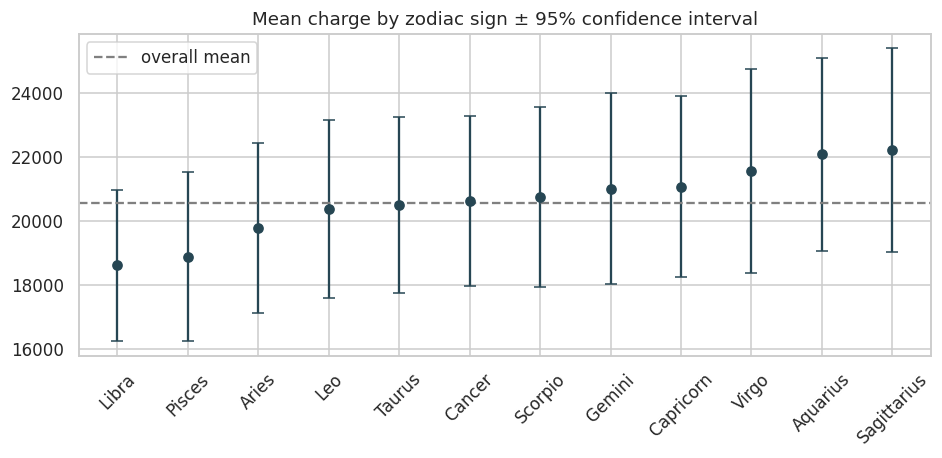

Observed zodiac spread = 17.5%. Random shuffles produced a spread at least this large 84% of the time (median random spread = 22.1%).
Smoker share by sign (lowest → highest): {'Libra': 0.21, 'Aries': 0.24, 'Leo': 0.26, 'Taurus': 0.28, 'Gemini': 0.3, 'Virgo': 0.31, 'Sagittarius': 0.32, 'Pisces': 0.33, 'Scorpio': 0.34, 'Cancer': 0.35, 'Capricorn': 0.36, 'Aquarius': 0.37}


In [11]:
z = df.groupby('zodiac_sign')['annual_charge'].agg(['count', 'mean', 'std'])
z['ci95'] = 1.96 * z['std'] / np.sqrt(z['count']); z = z.sort_values('mean')
plt.figure(figsize=(10, 3.8))
plt.errorbar(z.index, z['mean'], yerr=z['ci95'], fmt='o', capsize=4, color='#264653')
plt.axhline(df['annual_charge'].mean(), ls='--', c='grey', label='overall mean'); plt.legend()
plt.xticks(rotation=45); plt.title('Mean charge by zodiac sign ± 95% confidence interval'); plt.show()

def spread_of(labels):
    g = df['annual_charge'].groupby(labels).mean()
    return (g.max() - g.min()) / df['annual_charge'].mean()
obs = spread_of(df['zodiac_sign'].values)
rng = np.random.default_rng(RANDOM_STATE)
perm = np.array([spread_of(rng.permutation(df['zodiac_sign'].values)) for _ in range(1000)])
print(f"Observed zodiac spread = {obs:.1%}. Random shuffles produced a spread at least this large "
      f"{(perm >= obs).mean():.0%} of the time (median random spread = {np.median(perm):.1%}).")
sm_share = df.groupby('zodiac_sign')['smoker'].apply(lambda s: (s == 'yes').mean()).sort_values()
print("Smoker share by sign (lowest → highest):", sm_share.round(2).to_dict())

**Step 3 — decide and drop.**

In [12]:
drop_cols = ['customer_id']
drop_cols += ['favorite_color', 'zodiac_sign', 'lucky_number', 'preferred_contact', 'marketing_opt_in']   # YOUR CHOICE
df_model = df.drop(columns=drop_cols)
print("Dropped as irrelevant:", drop_cols)
print("Kept columns:", list(df_model.columns))

Dropped as irrelevant: ['customer_id', 'favorite_color', 'zodiac_sign', 'lucky_number', 'preferred_contact', 'marketing_opt_in']
Kept columns: ['age', 'sex', 'bmi', 'weight_kg', 'children', 'smoker', 'region', 'exercise_freq', 'date_of_birth', 'annual_charge', 'risk_tier']


### ✍️ Reflection A4

1. **Dropped as irrelevant:** `customer_id` (a row label), `favorite_color` (a taste, not a health trait), `zodiac_sign` (birth month has no causal link to claims), `lucky_number` (a number the customer picked at random), `preferred_contact` (how we message them), `marketing_opt_in` (a marketing preference). The evidence agrees: all five have Kruskal-Wallis p-values between **0.44 and 0.98** — no evidence their groups differ in cost.
2. `lucky_number` correlation = **−0.031**, essentially zero. That is expected: a number picked for luck carries no information about health, so any correlation is just random noise.
3. **The zodiac trap.** `zodiac_sign` shows a **17.5%** spread — the second biggest after smoking — but it has **12 categories with only 83–122 customers each**. With many small groups, *some* group will look expensive by luck. My permutation test shuffled the signs randomly 1,000 times: a spread at least this large appeared **84% of the time** (median random spread 22.1%), and ANOVA p = 0.82. The confidence-interval plot shows every sign overlapping the overall mean. The small differences that do exist line up with the smoker share per sign (21% for Libra to 37% for Aquarius) — a confounder, not astrology. Before trusting such a pattern I would check group sizes, confidence intervals, a significance test that accounts for many categories, confounders like smoking, and whether it repeats on new data.
   *Borderline columns I kept:* `sex` (ANOVA p = 0.008 but Kruskal p = 0.18 — ambiguous; A5 shows it matters within tiers) and `region` (p = 0.23–0.65; plausible because medical prices vary by area — Lasso will judge it).
4. Noted — `weight_kg`/`bmi` and `age`/`date_of_birth` are handled in A6.

## Task A5 — Hypothesis Testing

In [13]:
smokers    = df[df['smoker']=='yes']['annual_charge']
nonsmokers = df[df['smoker']=='no']['annual_charge']
t_stat, p_val = stats.ttest_ind(smokers, nonsmokers, equal_var=False)
print(f"Welch t-test      : t = {t_stat:.3f}, p-value = {p_val:.3g}")
u, p_u = stats.mannwhitneyu(smokers, nonsmokers)
print(f"Mann-Whitney U    : p-value = {p_u:.3g}   (no normality assumption — safer for skewed charges)")
cohen_d = (smokers.mean() - nonsmokers.mean()) / np.sqrt((smokers.var() + nonsmokers.var()) / 2)
print(f"Effect size       : Cohen's d = {cohen_d:.2f}  (0.8+ is conventionally 'large')")

r, p_corr = stats.pearsonr(df['age'], df['annual_charge'])
print(f"\nage vs charge     : r = {r:.3f}, p = {p_corr:.3g}")
for t in TIERS:
    s = df[df['risk_tier'] == t]; rt, pt = stats.pearsonr(s['age'], s['annual_charge'])
    print(f"   within {t:6} tier: r = {rt:.3f}, p = {pt:.3g}")
chi2, p_chi, dof, _ = stats.chi2_contingency(pd.crosstab(df['smoker'], df['risk_tier']))
print(f"\nsmoker vs risk_tier (chi-square): χ² = {chi2:.1f}, dof = {dof}, p = {p_chi:.3g}")

Welch t-test      : t = 24.083, p-value = 2.27e-84
Mann-Whitney U    : p-value = 3.67e-120   (no normality assumption — safer for skewed charges)
Effect size       : Cohen's d = 1.65  (0.8+ is conventionally 'large')

age vs charge     : r = 0.410, p = 6.88e-50
   within Low    tier: r = 0.624, p = 1.62e-34
   within Medium tier: r = 0.142, p = 0.000353
   within High   tier: r = 0.038, p = 0.54

smoker vs risk_tier (chi-square): χ² = 424.7, dof = 2, p = 6.09e-93


In [14]:
# Extra: sex looks like it matters overall — but is that real, or a mix effect?
print("Mean charge by sex (overall):", df.groupby('sex')['annual_charge'].mean().round(0).to_dict())
display(df.pivot_table(index='risk_tier', columns='sex', values='annual_charge', aggfunc='mean').reindex(TIERS).round(0))
display(pd.crosstab(df['sex'], df['risk_tier'], normalize='index')[TIERS].round(3))

Mean charge by sex (overall): {'female': 21646.0, 'male': 19468.0}


sex,female,male
risk_tier,,
Low,7379.0,7771.0
Medium,15875.0,16204.0
High,45395.0,46624.0


risk_tier,Low,Medium,High
sex,,,
female,0.235,0.503,0.263
male,0.277,0.539,0.184


### ✍️ Reflection A5

1. **H₀:** the mean annual charge of smokers equals that of non-smokers. **H₁:** the means differ (smokers pay more).
2. t = **24.08**, p ≈ **2 × 10⁻⁸⁴** → far below 0.05, so I **reject H₀**. In business language: if smoking truly made no difference, the chance of seeing a gap this large in 1,200 customers is effectively zero — the extra ~$20k is real, not luck. The Mann-Whitney test (which does not assume normal data, safer for skewed charges) agrees (p ≈ 4 × 10⁻¹²⁰), and **Cohen's d = 1.65** says the effect is huge, not just statistically detectable.
3. Age vs charge: **r = 0.41, p ≈ 7 × 10⁻⁵⁰** → a real, moderate positive link: older customers cost more. But *inside* the tiers it fades: r = **0.62 in Low**, 0.14 in Medium, **0.04 (not significant) in High**. Age mostly works by pushing people into higher tiers; once someone is High, their age adds little. The chi-square test (p ≈ 6 × 10⁻⁹³) confirms smoking strongly determines the tier.
   *Extra — a Simpson's paradox on sex:* women cost more overall ($21,646 vs $19,468), but **inside every tier men cost more** (+$392 Low, +$329 Medium, +$1,229 High). The overall pattern flips because 26.3% of women are High-tier vs 18.4% of men. So `sex` stays as a feature — its real effect only shows once the tier is accounted for.

## Task A6 — Redundancy & Multicollinearity (VIF)

age vs date_of_birth corr: 1.0
bmi vs weight_kg  corr   : 0.992


,feature,"VIF (template, no constant)",VIF (with constant — correct)
0,age,1.01,1.01
1,bmi,67.48,67.48
2,weight_kg,66.16,66.16
3,children,1.00,1.00
4,exercise_freq,2.56,2.56


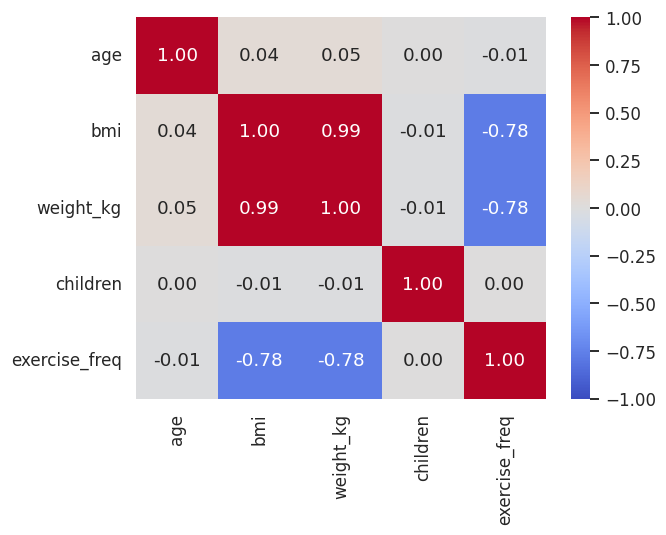

In [15]:
df['age_from_dob'] = 2026 - pd.to_datetime(df['date_of_birth']).dt.year
print("age vs date_of_birth corr:", round(df['age'].corr(df['age_from_dob']), 3))
print("bmi vs weight_kg  corr   :", round(df['bmi'].corr(df['weight_kg']), 3))

num_feats = ['age','bmi','weight_kg','children','exercise_freq']
Xv = df[num_feats].dropna()
vif = pd.DataFrame({'feature': num_feats,
                    'VIF (template, no constant)': [variance_inflation_factor(Xv.values, i) for i in range(len(num_feats))]})
Xc = sm.add_constant(Xv).values
vif['VIF (with constant — correct)'] = [variance_inflation_factor(Xc, i + 1) for i in range(len(num_feats))]
display(vif.round(2))
plt.figure(figsize=(6, 4.5)); sns.heatmap(df[num_feats].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1); plt.show()

In [16]:
# YOUR CHOICE: keep the more interpretable column of each redundant pair
df_model = df_model.drop(columns=['weight_kg', 'date_of_birth'])
keep = ['age', 'bmi', 'children', 'exercise_freq']
Xc2 = sm.add_constant(df_model[keep]).values
display(pd.DataFrame({'feature': keep, 'VIF after dropping': [variance_inflation_factor(Xc2, i + 1) for i in range(len(keep))]}).round(2))
print("Final feature columns:", list(df_model.columns))

,feature,VIF after dropping
0,age,1.00
1,bmi,2.56
2,children,1.00
3,exercise_freq,2.56


Final feature columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'exercise_freq', 'annual_charge', 'risk_tier']


### ✍️ Reflection A6

1. `bmi` vs `weight_kg`: **r = 0.992**. `age` vs `date_of_birth`: **r = 1.0** — age is literally computed from the birth date.
2. **VIF above 10:** `bmi` (**67.5**) and `weight_kg` (**66.2**) — the worst offending pair by far. Everything else is fine: `age` 1.01, `children` 1.00, `exercise_freq` 2.56 (mild, because active people have lower BMI; r = −0.78). *(The template's no-constant VIF can print different numbers on some statsmodels versions; the with-constant column is the textbook definition. Both agree on the conclusion.)* `date_of_birth` is not in the VIF table because it is a date, but at r = 1.0 it is perfectly redundant.
3. **Keep `bmi`, drop `weight_kg`:** BMI already adjusts weight for height (100 kg is healthy at 1.95 m and obese at 1.60 m), it is the measure clinicians and underwriters use (obesity = BMI ≥ 30), and it is the one the tier rules depend on. **Keep `age`, drop `date_of_birth`:** age is what drives cost, it is immediately interpretable, and a birth date would need a reference date and changes meaning every year. After dropping, every VIF is ≤ 2.56.

## Task A7 — Encode, Engineer Features & Frame Bias vs. Variance

In [17]:
df_model = pd.get_dummies(df_model, columns=['sex','smoker','region'], drop_first=True, dtype=int)
display(df_model.head())

,age,bmi,children,exercise_freq,annual_charge,risk_tier,sex_male,smoker_yes,region_north,region_south,region_west
0,56,29.7,1,3.0,14924.08,Medium,0,0,0,1,0
1,46,24.1,4,5.0,45450.69,High,0,1,0,0,1
2,32,34.4,0,3.0,43874.19,High,0,1,1,0,0
3,60,27.0,0,4.0,48107.39,High,0,1,1,0,0
4,25,31.3,1,4.0,13745.61,Medium,1,0,1,0,0


**Feature engineering.** The tree-like staircase below (average tier by age band × BMI band) shows that tiers jump at **BMI 30** (the WHO obesity line), **age 45** and again at **age 58**, and smokers sit one step higher. Distance- and probability-based models (KNN, Naive Bayes, Logistic Regression) can't draw sharp steps on their own, so I hand them the steps as 0/1 flags.

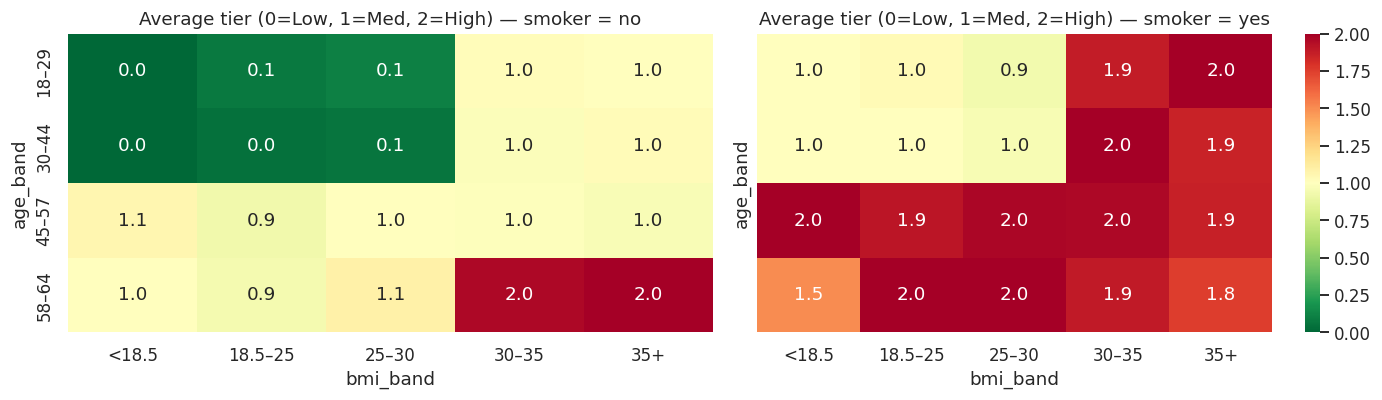

In [18]:
tmp = df.assign(age_band=pd.cut(df['age'], [17, 29, 44, 57, 64], labels=['18–29', '30–44', '45–57', '58–64']),
                bmi_band=pd.cut(df['bmi'], [0, 18.5, 25, 30, 35, 60], right=False, labels=['<18.5', '18.5–25', '25–30', '30–35', '35+']),
                tier_score=df['risk_tier'].map({'Low': 0, 'Medium': 1, 'High': 2}))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a, s in zip(ax, ['no', 'yes']):
    ct = tmp[tmp['smoker'] == s].pivot_table(index='age_band', columns='bmi_band', values='tier_score', aggfunc='mean', observed=False)
    sns.heatmap(ct, annot=True, fmt='.1f', cmap='RdYlGn_r', vmin=0, vmax=2, ax=a, cbar=(s == 'yes'))
    a.set_title(f'Average tier (0=Low, 1=Med, 2=High) — smoker = {s}')
plt.tight_layout(); plt.show()

In [19]:
# Engineered-feature helpers (the same functions are reused in Part E and in app.py)
ENG = ['obese', 'age_45plus', 'age_58plus', 'smoker_obese']

def _smoker01(d):
    if 'smoker_yes' in d.columns:
        return d['smoker_yes'].astype(int)
    return (d['smoker'].astype(str).str.strip().str.lower() == 'yes').astype(int)


def add_features(d):
    """Threshold flags suggested by the EDA (WHO obesity cut-off, age bands)."""
    d = d.copy()
    d['obese'] = (d['bmi'] >= 30).astype(int)
    d['age_45plus'] = (d['age'] >= 45).astype(int)
    d['age_58plus'] = (d['age'] >= 58).astype(int)
    d['smoker_obese'] = _smoker01(d) * d['obese']
    return d


def risk_points(d):
    """Transparent scorecard: 2×smoker + 1×(BMI≥30) + 1×(age≥45) + 1×(age≥58)."""
    return (2 * _smoker01(d) + (d['bmi'] >= 30).astype(int)
            + (d['age'] >= 45).astype(int) + (d['age'] >= 58).astype(int))


def scorecard_tier(points):
    points = np.asarray(points)
    return np.select([points == 0, points <= 2], ['Low', 'Medium'], 'High')

df_fe = add_features(df_model)
display(df_fe[['age', 'bmi', 'smoker_yes'] + ENG].head())

,age,bmi,smoker_yes,obese,age_45plus,age_58plus,smoker_obese
0,56,29.7,0,0,1,0,0
1,46,24.1,1,0,1,0,0
2,32,34.4,1,1,0,0,1
3,60,27.0,1,0,1,1,0
4,25,31.3,0,1,0,0,0


### ✍️ Reflection A7

1. `drop_first=True` removes one dummy per categorical (e.g. keeps `sex_male`, drops `sex_female`) because the dropped one is implied: female = 1 − male. Keeping all of them makes the dummies add up to exactly 1 for every row, which duplicates the intercept (the **dummy-variable trap**) — perfect multicollinearity, so the regression cannot find unique coefficients.
2. **Underfitting (high bias):** a too-simple model — e.g. one flat price or one straight line for everyone — charges a young non-smoker and an older obese smoker almost the same. Business consequence: exactly today's problem, Low-risk customers overpay and leave, High-risk ones underpay and create claim losses. **Overfitting (high variance):** a model that memorises noise (a very deep tree, or one that learned the zodiac quirks) gives two near-identical customers wildly different quotes and fails on new customers. Consequence: unstable, unfair, unexplainable prices, complaints and regulatory risk, and a model whose promised accuracy disappears in production.
3. **Low training error + high test error = overfitting (high variance).** Fix: simplify (fewer features, prune/limit tree depth), regularise (Ridge/Lasso, larger alpha), use cross-validation to tune, or collect more data.
   *Feature engineering:* the heatmap shows the tier rising in steps at **BMI 30**, **age 45** and **age 58**, with smokers one step higher. I added four 0/1 flags (`obese`, `age_45plus`, `age_58plus`, `smoker_obese`) so that distance- and probability-based models can "see" those steps. Part B tests whether this helps.

## Task A8 — Automated Feature Selection with Lasso (confirm the audit) ⭐

In [20]:
audit = df.drop(columns=['customer_id','date_of_birth','annual_charge','risk_tier','age_from_dob'])
audit = pd.get_dummies(audit, columns=['sex','smoker','region','favorite_color','zodiac_sign',
                                       'preferred_contact','marketing_opt_in'], drop_first=True).astype(float)
feat_names = audit.columns
X, y = audit.values, df['annual_charge'].values
Xtr_a, Xte_a, ytr_a, yte_a = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
sc = StandardScaler().fit(Xtr_a)
JUNK = ('favorite_color', 'zodiac_sign', 'lucky_number', 'preferred_contact', 'marketing_opt_in')

for a in [10, 100, 400, 800]:
    l = Lasso(alpha=a, max_iter=50000).fit(sc.transform(Xtr_a), ytr_a)
    kept = [f for f, c in zip(feat_names, l.coef_) if abs(c) > 1]
    junk_kept = [f for f in kept if f.startswith(JUNK)]
    r2 = r2_score(yte_a, l.predict(sc.transform(Xte_a)))
    print(f"alpha={a:4} | R²={r2:.3f} | features kept ({len(kept):2}) | junk still in: {len(junk_kept):2} → {kept}")

alpha=  10 | R²=0.685 | features kept (29) | junk still in: 19 → ['age', 'bmi', 'weight_kg', 'children', 'exercise_freq', 'lucky_number', 'sex_male', 'smoker_yes', 'region_north', 'region_south', 'region_west', 'favorite_color_green', 'favorite_color_purple', 'favorite_color_red', 'favorite_color_yellow', 'zodiac_sign_Aries', 'zodiac_sign_Cancer', 'zodiac_sign_Capricorn', 'zodiac_sign_Gemini', 'zodiac_sign_Leo', 'zodiac_sign_Libra', 'zodiac_sign_Pisces', 'zodiac_sign_Sagittarius', 'zodiac_sign_Scorpio', 'zodiac_sign_Taurus', 'zodiac_sign_Virgo', 'preferred_contact_phone', 'preferred_contact_sms', 'marketing_opt_in_yes']
alpha= 100 | R²=0.690 | features kept (18) | junk still in: 10 → ['age', 'bmi', 'weight_kg', 'children', 'lucky_number', 'sex_male', 'smoker_yes', 'region_north', 'region_south', 'favorite_color_green', 'favorite_color_purple', 'favorite_color_yellow', 'zodiac_sign_Aries', 'zodiac_sign_Cancer', 'zodiac_sign_Libra', 'zodiac_sign_Pisces', 'zodiac_sign_Taurus', 'marketing_

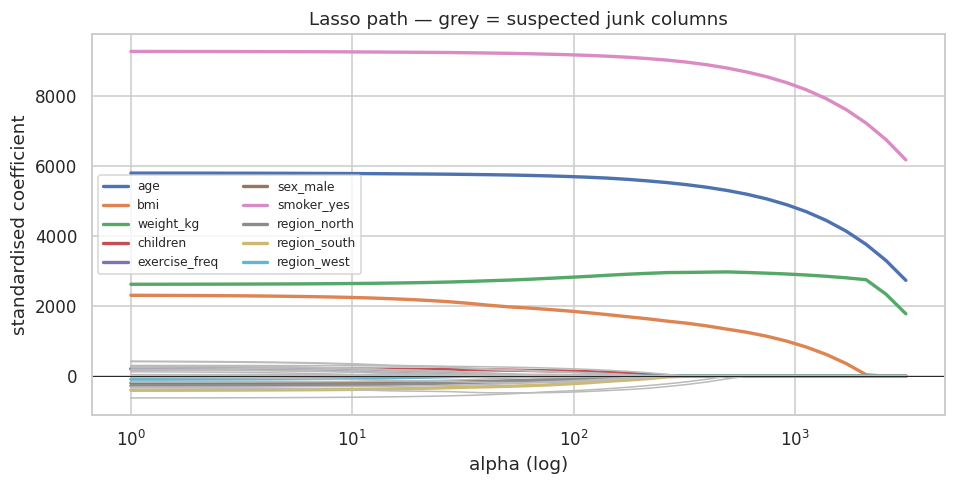

OLS test R² with ALL 29 columns: 0.684  |  with the 9 cleaned columns: 0.695


In [21]:
# Lasso path: watch junk coefficients die first
alphas_path = np.logspace(0, 3.5, 40)
coefs = np.array([Lasso(alpha=a, max_iter=50000).fit(sc.transform(Xtr_a), ytr_a).coef_ for a in alphas_path])
plt.figure(figsize=(10, 4.5))
for j, f in enumerate(feat_names):
    is_junk = f.startswith(JUNK)
    plt.plot(alphas_path, coefs[:, j], color='#bbbbbb' if is_junk else None, lw=1 if is_junk else 2.2,
             label=None if is_junk else f)
plt.xscale('log'); plt.axhline(0, c='k', lw=.6); plt.xlabel('alpha (log)'); plt.ylabel('standardised coefficient')
plt.title('Lasso path — grey = suspected junk columns'); plt.legend(fontsize=8, ncol=2); plt.show()

# Same split, plain OLS: all columns vs the cleaned columns
clean_cols = [f for f in feat_names if not f.startswith(JUNK) and f != 'weight_kg']
ci = [list(feat_names).index(f) for f in clean_cols]
r2_all = r2_score(yte_a, LinearRegression().fit(Xtr_a, ytr_a).predict(Xte_a))
r2_clean = r2_score(yte_a, LinearRegression().fit(Xtr_a[:, ci], ytr_a).predict(Xte_a[:, ci]))
print(f"OLS test R² with ALL {len(feat_names)} columns: {r2_all:.3f}  |  with the {len(clean_cols)} cleaned columns: {r2_clean:.3f}")

### ✍️ Reflection A8

1. At **α = 10** Lasso keeps 29 features including **19 junk dummies**; at **α = 100**, 18 kept (10 junk, `lucky_number` still in); at **α = 400**, 6 kept, with just 2 junk dummies hanging on (`favorite_color_green`, `zodiac_sign_Pisces`, tiny coefficients); at **α = 800** only **`age`, `bmi`, `weight_kg`, `smoker_yes`** survive — **zero junk**. The Lasso-path plot shows every grey (junk) line collapsing to zero early.
2. R² barely moves: **0.685 → 0.690 → 0.692 → 0.686** as the junk disappears. On the same split, plain OLS scores **0.684 with all 29 columns vs 0.695 with my 9 cleaned columns** — removing the junk actually *improves* test performance slightly. That proves the junk carries no signal; it only adds noise and the risk of overfitting.
3. **Yes, Lasso agrees** with every irrelevant column I dropped in A4. Two differences, both explainable: (a) at α = 800 Lasso keeps *both* `bmi` and `weight_kg` — Lasso has no business sense about redundancy, so the VIF decision in A6 still stands; (b) at strong α it also drops `children`, `sex`, `region` and `exercise_freq`. Those are weak in a *global* linear model but — as C4 shows — `children` and `sex` matter *within* tiers, so I keep them.

# PART B — STAGE 1: Classify the Customer (Risk Tier)

## Task B1 — Build the Classifiers

In [22]:
X_cls = df_model.drop(columns=['annual_charge', 'risk_tier'])
y_cls = df_model['risk_tier']
Xtr, Xte, ytr, yte = train_test_split(X_cls, y_cls, test_size=0.2, random_state=RANDOM_STATE, stratify=y_cls)
idx_tr, idx_te = Xtr.index, Xte.index            # the same rows are reused by every model below
print("train:", Xtr.shape, " test:", Xte.shape)
print("tier share — train:", ytr.value_counts(normalize=True).round(3).to_dict())
print("tier share — test :", yte.value_counts(normalize=True).round(3).to_dict())

train: (960, 9)  test: (240, 9)
tier share — train: {'Medium': 0.521, 'Low': 0.256, 'High': 0.223}
tier share — test : {'Medium': 0.521, 'Low': 0.254, 'High': 0.225}


### How a decision tree chooses a split — Gini vs Entropy, by hand
- **Gini impurity** $= 1-\sum_k p_k^2$ → "chance two random customers in this node have different tiers".
- **Entropy** $= -\sum_k p_k \log_2 p_k$ → "bits of surprise left in this node".
- A split is good if the **weighted impurity of the children** is much lower than the parent. For entropy that drop is called **information gain**.

In [23]:
def gini(s):    p = s.value_counts(normalize=True); return 1 - (p ** 2).sum()
def entropy(s): p = s.value_counts(normalize=True); return -(p * np.log2(p)).sum()
print(f"Root node (training set): Gini = {gini(ytr):.3f}   Entropy = {entropy(ytr):.3f} bits")
rows = []
for name, mask in {'smoker = yes': Xtr['smoker_yes'] == 1, 'age ≥ 45': Xtr['age'] >= 45, 'bmi ≥ 30': Xtr['bmi'] >= 30,
                   'exercise ≤ 2': Xtr['exercise_freq'] <= 2, 'sex = male': Xtr['sex_male'] == 1,
                   'children ≥ 2': Xtr['children'] >= 2}.items():
    L, R = ytr[mask], ytr[~mask]; wL, wR = len(L) / len(ytr), len(R) / len(ytr)
    rows.append({'candidate split': name, 'Gini decrease': gini(ytr) - (wL * gini(L) + wR * gini(R)),
                 'Information gain': entropy(ytr) - (wL * entropy(L) + wR * entropy(R))})
display(pd.DataFrame(rows).sort_values('Information gain', ascending=False).set_index('candidate split').round(4))

Root node (training set): Gini = 0.613   Entropy = 1.476 bits


,Gini decrease,Information gain
candidate split,,
smoker = yes,0.0823,0.2726
age ≥ 45,0.0608,0.2074
bmi ≥ 30,0.0483,0.1684
exercise ≤ 2,0.0072,0.0251
sex = male,0.0012,0.0034
children ≥ 2,0.0001,0.0003


### Train and tune five classifiers — on raw features, then on raw + engineered flags

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
Xtr_fe = df_fe.loc[idx_tr, list(X_cls.columns) + ENG]
Xte_fe = df_fe.loc[idx_te, list(X_cls.columns) + ENG]
tree_grid = {'max_depth': [2, 3, 4, 5, 6, 8, 10, None], 'min_samples_leaf': [1, 5, 10, 20]}
candidates = {
    'Naive Bayes (Gaussian)':  (GaussianNB(), {}),
    'KNN':                     (Pipeline([('sc', StandardScaler()), ('m', KNeighborsClassifier())]),
                                {'m__n_neighbors': [3, 5, 7, 9, 11, 15, 21, 31], 'm__weights': ['uniform', 'distance']}),
    'Decision Tree (Gini)':    (DecisionTreeClassifier(criterion='gini', random_state=RANDOM_STATE), tree_grid),
    'Decision Tree (Entropy)': (DecisionTreeClassifier(criterion='entropy', random_state=RANDOM_STATE), tree_grid),
    'Logistic Regression':     (Pipeline([('sc', StandardScaler()), ('m', LogisticRegression(max_iter=5000))]),
                                {'m__C': [0.01, 0.1, 1, 10, 100]}),
}
results, fitted, best_params = [], {}, {}
for fs, (A, B) in {'raw': (Xtr, Xte), 'raw + engineered': (Xtr_fe, Xte_fe)}.items():
    for name, (est, grid) in candidates.items():
        gs = GridSearchCV(est, grid, cv=cv, scoring='accuracy').fit(A, ytr)
        m = gs.best_estimator_; p = m.predict(B)
        fitted[(fs, name)] = m; best_params[(fs, name)] = gs.best_params_
        results.append({'features': fs, 'model': name, 'CV acc (train)': gs.best_score_,
                        'train acc': accuracy_score(ytr, m.predict(A)), 'test acc': accuracy_score(yte, p),
                        'test macro-F1': f1_score(yte, p, average='macro'), 'best params': gs.best_params_})

# Naive Bayes, categorical flavour: bin the continuous features first
def to_bins(d):
    return pd.DataFrame({'age_band': pd.cut(d['age'], [0, 29, 44, 57, 200], labels=False),
                         'bmi_band': pd.cut(d['bmi'], [0, 18.5, 25, 30, 35, 200], labels=False, right=False),
                         'smoker': d['smoker_yes'],
                         'exercise_band': pd.cut(d['exercise_freq'], [-1, 2, 4, 7], labels=False)}, index=d.index)
cnb = CategoricalNB().fit(to_bins(Xtr), ytr); p = cnb.predict(to_bins(Xte))
results.append({'features': 'binned', 'model': 'Naive Bayes (Categorical)',
                'CV acc (train)': cross_val_score(CategoricalNB(), to_bins(Xtr), ytr, cv=cv).mean(),
                'train acc': accuracy_score(ytr, cnb.predict(to_bins(Xtr))), 'test acc': accuracy_score(yte, p),
                'test macro-F1': f1_score(yte, p, average='macro'), 'best params': {}})
res = pd.DataFrame(results)
display(res.drop(columns='best params').round(3))

,features,model,CV acc (train),train acc,test acc,test macro-F1
0,raw,Naive Bayes (Gaussian),0.752,0.770,0.796,0.791
1,raw,KNN,0.779,1.000,0.833,0.822
2,raw,Decision Tree (Gini),0.930,0.935,0.954,0.954
3,raw,Decision Tree (Entropy),0.932,0.935,0.954,0.954
4,raw,Logistic Regression,0.777,0.788,0.838,0.829
5,raw + engineered,Naive Bayes (Gaussian),0.777,0.797,0.783,0.780
6,raw + engineered,KNN,0.925,1.000,0.950,0.949
7,raw + engineered,Decision Tree (Gini),0.933,0.935,0.954,0.954
8,raw + engineered,Decision Tree (Entropy),0.932,0.935,0.954,0.954
9,raw + engineered,Logistic Regression,0.935,0.935,0.954,0.954


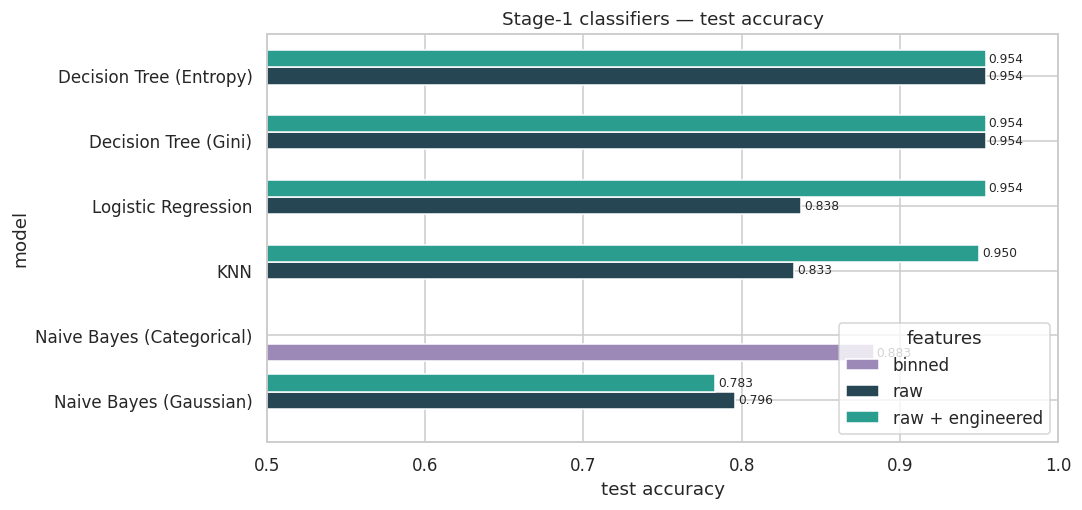

raw               | Naive Bayes (Gaussian)   | {}
raw               | KNN                      | {'m__n_neighbors': 7, 'm__weights': 'distance'}
raw               | Decision Tree (Gini)     | {'max_depth': 4, 'min_samples_leaf': 5}
raw               | Decision Tree (Entropy)  | {'max_depth': 4, 'min_samples_leaf': 5}
raw               | Logistic Regression      | {'m__C': 10}
raw + engineered  | Naive Bayes (Gaussian)   | {}
raw + engineered  | KNN                      | {'m__n_neighbors': 7, 'm__weights': 'distance'}
raw + engineered  | Decision Tree (Gini)     | {'max_depth': 5, 'min_samples_leaf': 10}
raw + engineered  | Decision Tree (Entropy)  | {'max_depth': 4, 'min_samples_leaf': 5}
raw + engineered  | Logistic Regression      | {'m__C': 1}


In [25]:
piv = res.pivot_table(index='model', columns='features', values='test acc').reindex(
    ['Naive Bayes (Gaussian)', 'Naive Bayes (Categorical)', 'KNN', 'Logistic Regression', 'Decision Tree (Gini)', 'Decision Tree (Entropy)'])
ax = piv.plot.barh(figsize=(10, 4.8), color=['#9c89b8', '#264653', '#2a9d8f'], width=.8)
ax.set_xlim(0.5, 1.0); ax.set_xlabel('test accuracy'); ax.set_title('Stage-1 classifiers — test accuracy')
for c in ax.containers: ax.bar_label(c, fmt='%.3f', fontsize=8, padding=2)
plt.tight_layout(); plt.show()
for k, v in best_params.items(): print(f"{k[0]:17} | {k[1]:24} | {v}")

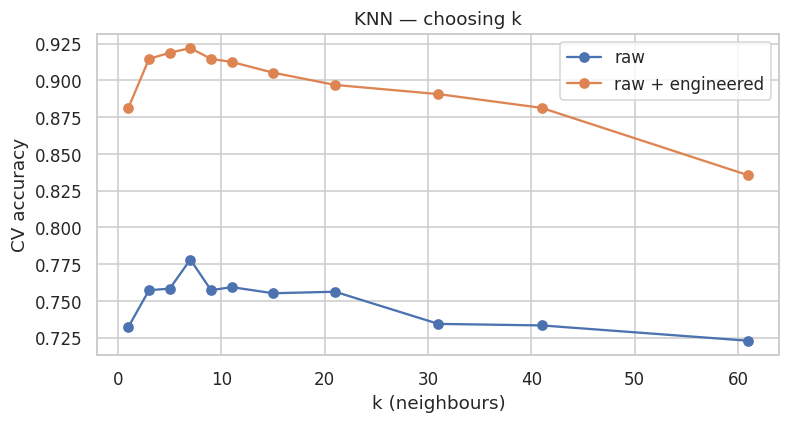

In [26]:
# KNN: how accuracy moves with k (5-fold CV on the training set)
ks = [1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 61]
plt.figure(figsize=(8, 3.8))
for fs, A in {'raw': Xtr, 'raw + engineered': Xtr_fe}.items():
    acc = [cross_val_score(Pipeline([('sc', StandardScaler()), ('m', KNeighborsClassifier(k))]), A, ytr, cv=cv).mean() for k in ks]
    plt.plot(ks, acc, marker='o', label=fs)
plt.xlabel('k (neighbours)'); plt.ylabel('CV accuracy'); plt.title('KNN — choosing k'); plt.legend(); plt.show()

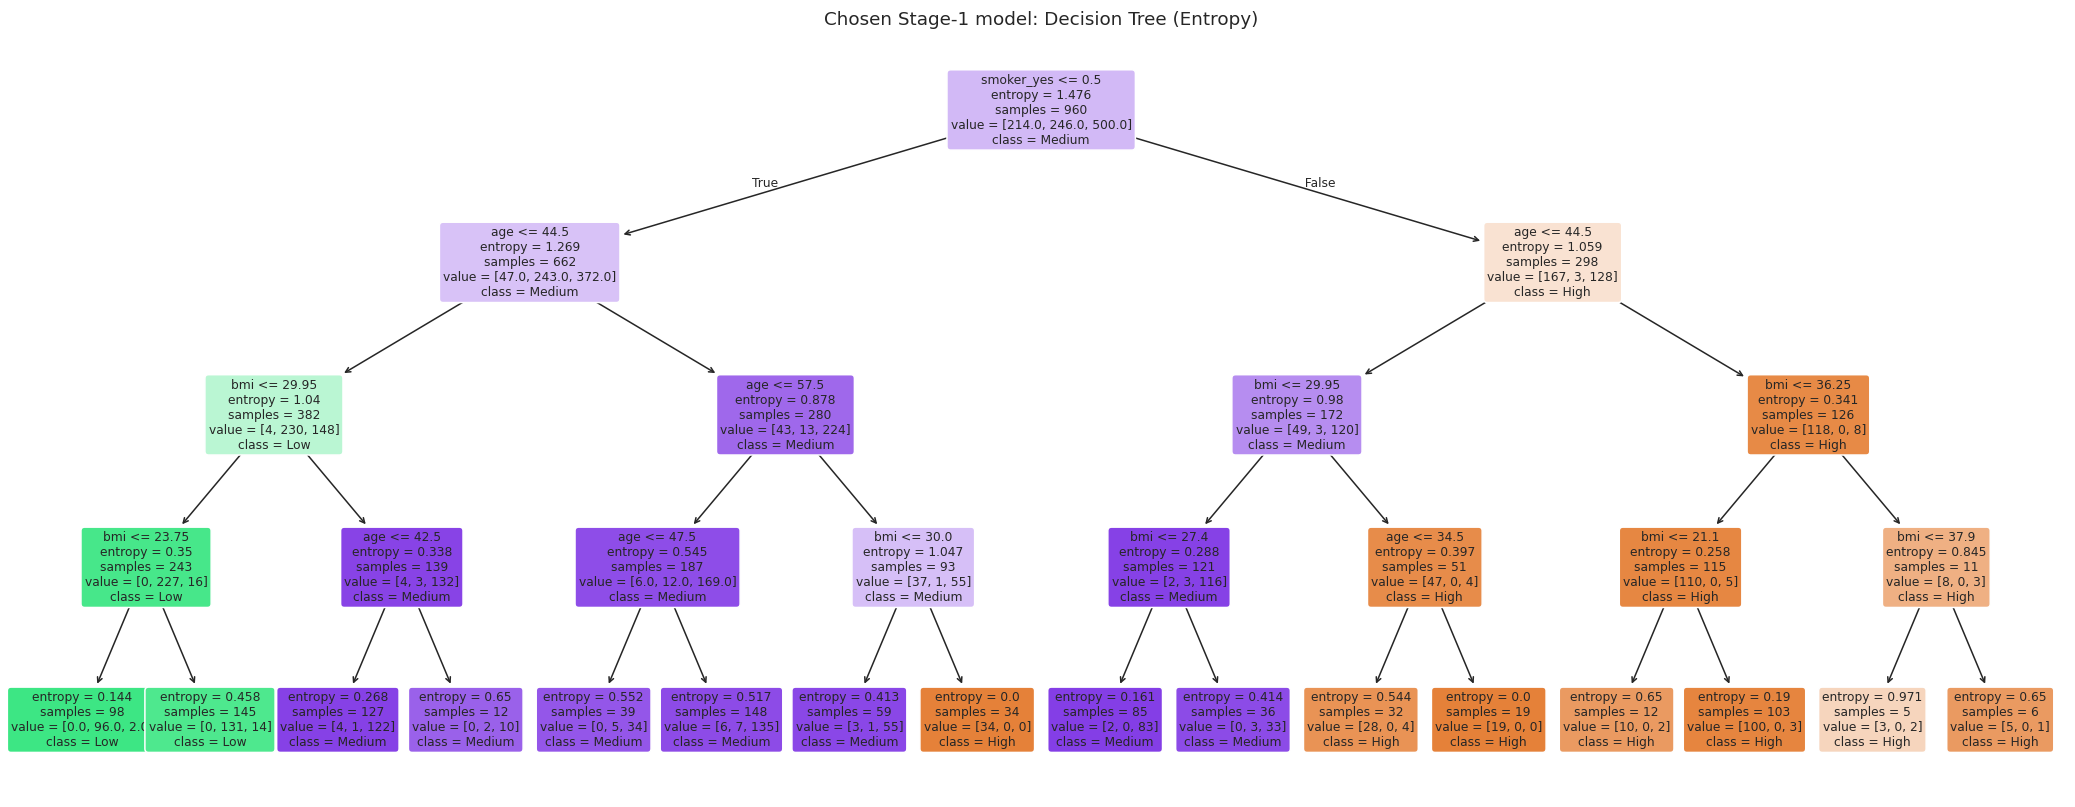

|--- smoker_yes <= 0.50
|   |--- age <= 44.50
|   |   |--- bmi <= 29.95
|   |   |   |--- bmi <= 23.75
|   |   |   |   |--- class: Low
|   |   |   |--- bmi >  23.75
|   |   |   |   |--- class: Low
|   |   |--- bmi >  29.95
|   |   |   |--- age <= 42.50
|   |   |   |   |--- class: Medium
|   |   |   |--- age >  42.50
|   |   |   |   |--- class: Medium
|   |--- age >  44.50
|   |   |--- age <= 57.50
|   |   |   |--- age <= 47.50
|   |   |   |   |--- class: Medium
|   |   |   |--- age >  47.50
|   |   |   |   |--- class: Medium
|   |   |--- age >  57.50
|   |   |   |--- bmi <= 30.00
|   |   |   |   |--- class: Medium
|   |   |   |--- bmi >  30.00
|   |   |   |   |--- class: High
|--- smoker_yes >  0.50
|   |--- age <= 44.50
|   |   |--- bmi <= 29.95
|   |   |   |--- bmi <= 27.40
|   |   |   |   |--- class: Medium
|   |   |   |--- bmi >  27.40
|   |   |   |   |--- class: Medium
|   |   |--- bmi >  29.95
|   |   |   |--- age <= 34.50
|   |   |   |   |--- class: High
|   |   |   |--- age >  3

In [27]:
clf = fitted[('raw', 'Decision Tree (Entropy)')]      # YOUR CHOICE — justified in Reflection B1
pred = clf.predict(Xte)
plt.figure(figsize=(24, 9))
plot_tree(clf, feature_names=X_cls.columns, class_names=list(clf.classes_), filled=True, rounded=True, fontsize=8,
          impurity=True, proportion=False)
plt.title('Chosen Stage-1 model: Decision Tree (Entropy)'); plt.show()
print(export_text(clf, feature_names=list(X_cls.columns)))
imp = pd.Series(clf.feature_importances_, index=X_cls.columns).sort_values(ascending=False)
print("Feature importance:", imp[imp > 0].round(3).to_dict())

### A formula a human can use — the **risk scorecard**
Reading the tree's splits (smoker → BMI 30 → age 45 → age 58) suggests a points system:

$$\text{Risk points} = 2\cdot\text{Smoker} + 1\cdot[\text{BMI}\ge 30] + 1\cdot[\text{Age}\ge 45] + 1\cdot[\text{Age}\ge 58]$$

**0 points → Low · 1–2 points → Medium · 3+ points → High.** Let's test it.

In [28]:
pts_all = risk_points(df_model)
display(pd.crosstab(pts_all.rename('risk points'), df_model['risk_tier'])[TIERS])
print(f"Scorecard accuracy — train: {accuracy_score(ytr, scorecard_tier(risk_points(Xtr))):.3f} | "
      f"test: {accuracy_score(yte, scorecard_tier(risk_points(Xte))):.3f} | tree test: {accuracy_score(yte, pred):.3f}")

risk_tier,Low,Medium,High
risk points,,,
0,284,19,0
1,10,298,8
2,13,294,9
3,0,8,170
4,0,4,70
5,0,2,11


Scorecard accuracy — train: 0.935 | test: 0.954 | tree test: 0.954


### ✍️ Reflection B1

1. **Decision Tree (Entropy), max_depth = 4, min_samples_leaf = 5** (tuned by 5-fold CV grid search on the training set). Reasons: (a) the **best test accuracy, 0.954** (tied with the Gini tree and the engineered Logistic Regression); (b) the tiers are defined by **thresholds** (BMI 30, age 45/58), which a tree models naturally while KNN/Naive Bayes cannot; (c) no scaling needed; (d) it is **explainable** — every decision is a readable path (smoker? → age ≥ 45? → BMI ≥ 30?) that staff, customers and regulators can audit, and it turns into the points **scorecard**, which gets the same 0.954 test accuracy.
   **Comparing the algorithms I tested:**
   - **Gini vs Entropy:** identical here (same best settings, same 0.954). Both rank "smoker = yes" as the best first split (information gain 0.273 bits; Gini decrease 0.082), then age ≥ 45, then BMI ≥ 30 — exactly the tree's top splits. The two criteria usually agree; entropy penalises mixed nodes slightly more.
   - **KNN:** 0.833 on raw features (and 1.000 on training — it memorises with distance weighting) → **0.950** once the threshold flags are added. Irrelevant dimensions (children, region, sex) dilute distances; the flags put customers on the same side of a threshold next to each other.
   - **Naive Bayes:** Gaussian 0.796 raw, **0.783 with flags (worse!)** — the flags repeat information already in BMI/age, which breaks NB's "features are independent" assumption and double-counts evidence. **Categorical NB on bands** reaches 0.883 because the tier really depends on bands, not smooth bell curves.
   - **Logistic Regression:** 0.838 raw → 0.954 with flags.
   The ceiling of ~93–95% for every good model is explained in Bonus 1 (about 6% of recorded tiers contradict the rules).
2. `stratify=y_cls` keeps the tier mix identical in train and test (52/26/22%: 0.521/0.256/0.223 in train vs 0.521/0.254/0.225 in test). Without it, the smallest class (High) could be under- or over-represented in the 240-row test set purely by chance, making the accuracy noisy and misleading.

## Task B2 — Evaluate the Classifier

In [29]:
print("Accuracy:", round(accuracy_score(yte, pred), 3))
cm = confusion_matrix(yte, pred, labels=TIERS)
print(pd.DataFrame(cm, index=[f'true {t}' for t in TIERS], columns=[f'pred {t}' for t in TIERS]))
print(classification_report(yte, pred, labels=TIERS))

Accuracy: 0.954
             pred Low  pred Medium  pred High
true Low           57            4          0
true Medium         3          121          1
true High           0            3         51
              precision    recall  f1-score   support

         Low       0.95      0.93      0.94        61
      Medium       0.95      0.97      0.96       125
        High       0.98      0.94      0.96        54

    accuracy                           0.95       240
   macro avg       0.96      0.95      0.95       240
weighted avg       0.95      0.95      0.95       240



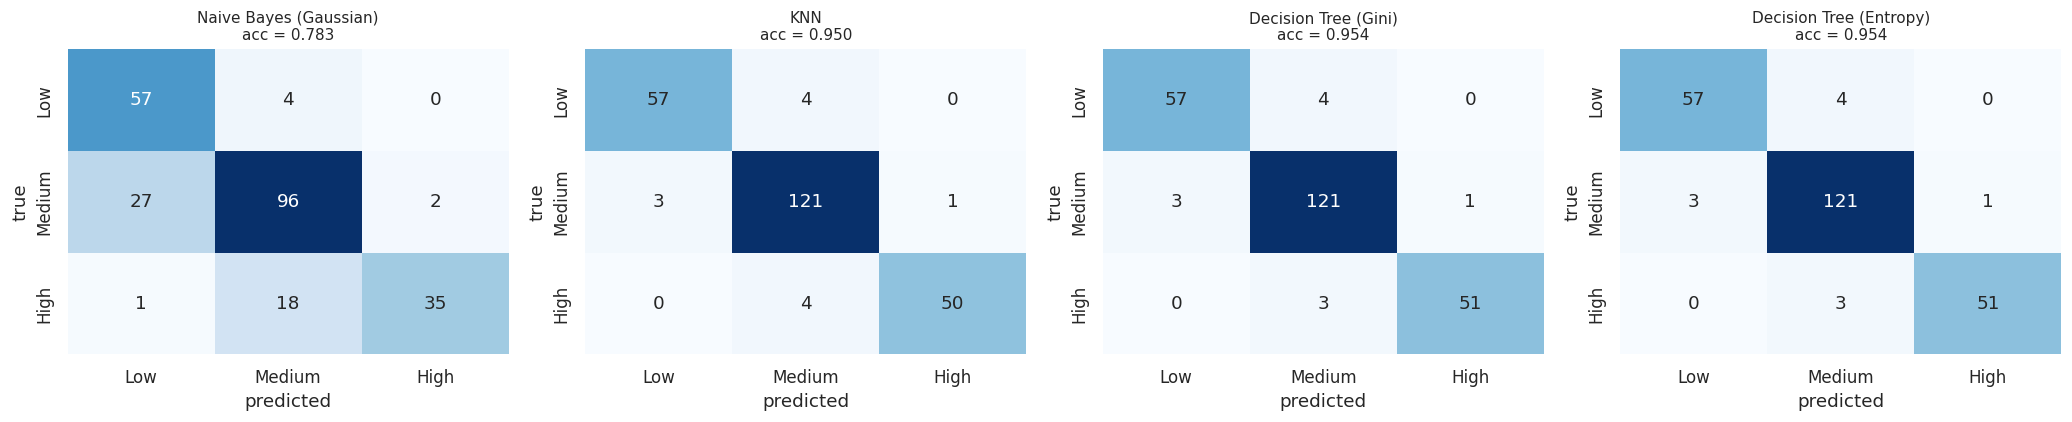

Dangerous errors (true High → predicted Low): 0 | Costly-to-customer errors (true Low → predicted High): 0


In [30]:
show = [('raw + engineered', 'Naive Bayes (Gaussian)'), ('raw + engineered', 'KNN'),
        ('raw', 'Decision Tree (Gini)'), ('raw', 'Decision Tree (Entropy)')]
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
for a, key in zip(ax, show):
    A = Xte_fe if key[0] != 'raw' else Xte
    c = confusion_matrix(yte, fitted[key].predict(A), labels=TIERS)
    sns.heatmap(c, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=TIERS, yticklabels=TIERS, ax=a)
    a.set_title(f"{key[1]}\nacc = {np.trace(c)/c.sum():.3f}", fontsize=10); a.set_xlabel('predicted'); a.set_ylabel('true')
plt.tight_layout(); plt.show()
hi_as_low = int(cm[TIERS.index('High'), TIERS.index('Low')]); low_as_hi = int(cm[TIERS.index('Low'), TIERS.index('High')])
print(f"Dangerous errors (true High → predicted Low): {hi_as_low} | Costly-to-customer errors (true Low → predicted High): {low_as_hi}")

### ✍️ Reflection B2

1. **Test accuracy = 0.954** (macro-F1 0.954; High recall 0.94, High precision 0.98).
2. The most confusion is between **Low and Medium** (4 Low → Medium, 3 Medium → Low) and **High → Medium** (3). There are **no Low ↔ High mistakes** at all — the model never jumps two tiers.
3. **Labelling a truly High customer as Low is far worse.** They would be priced with the Low-tier equation (~$7k) while their claims average ~$46k — a loss of roughly **$38,000 per customer**, and cheap quotes attract exactly these high-risk customers (adverse selection). Labelling a Low customer as High overcharges them ~5× — they leave for a competitor, which costs revenue and reputation, but HealthWise does not lose money on claims. So the cost is asymmetric: I care most about High-tier recall. In this test set both extreme errors are **0**; the realistic costly error is High → Medium (3 cases, each undercharged ~$21k — see Bonus 1).

## Task B3 — Bias/Variance Check

Train accuracy: 0.935
Test  accuracy: 0.954


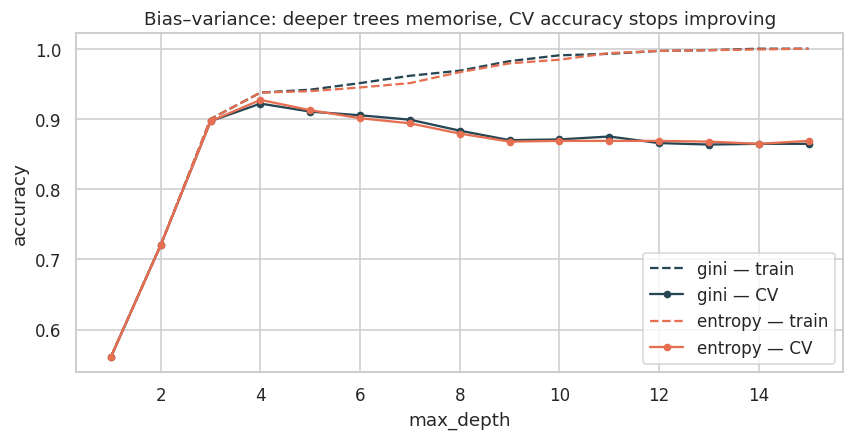

In [31]:
print("Train accuracy:", round(accuracy_score(ytr, clf.predict(Xtr)), 3))
print("Test  accuracy:", round(accuracy_score(yte, pred), 3))

depths = range(1, 16)
fig, ax = plt.subplots(figsize=(9, 4))
for crit, col in [('gini', '#264653'), ('entropy', '#e76f51')]:
    tr_acc, cv_acc = [], []
    for dpt in depths:
        mdl = DecisionTreeClassifier(criterion=crit, max_depth=dpt, random_state=RANDOM_STATE)
        tr_acc.append(mdl.fit(Xtr, ytr).score(Xtr, ytr)); cv_acc.append(cross_val_score(mdl, Xtr, ytr, cv=cv).mean())
    ax.plot(depths, tr_acc, '--', color=col, label=f'{crit} — train'); ax.plot(depths, cv_acc, '-o', color=col, ms=4, label=f'{crit} — CV')
ax.set_xlabel('max_depth'); ax.set_ylabel('accuracy'); ax.set_title('Bias–variance: deeper trees memorise, CV accuracy stops improving')
ax.legend(); plt.show()

### ✍️ Reflection B3

1. **Train 0.935 vs test 0.954** — no gap (test is even slightly higher by luck of a 240-row split; the 5-fold CV score of 0.932 confirms the true level is ~93%).
2. **Well-balanced.** The depth curve shows why depth 4 was chosen: training accuracy keeps climbing toward 1.0 as the tree gets deeper (memorising), while CV accuracy peaks around depth 4 and then flattens/drops — beyond that is overfitting. It is not underfitting either: every strong model (tree, engineered KNN, engineered Logistic Regression) hits the same ~93–95% ceiling, because about 6% of customers' recorded tiers contradict the rules and cannot be learned from these columns (Bonus 1).

# PART C — STAGE 2: Predict the Charge (Regression per Tier)

## Task C1 — The Baseline: ONE Global Regression

In [32]:
X_reg = df_model.drop(columns=['annual_charge', 'risk_tier'])
y_reg = df_model['annual_charge']
Xtr_r, Xte_r, ytr_r, yte_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE)

global_model = LinearRegression().fit(Xtr_r, ytr_r)
gp = global_model.predict(Xte_r)
print("GLOBAL model")
print("  MAE :", round(mean_absolute_error(yte_r, gp)))
print("  RMSE:", round(rmse(yte_r, gp)))
print("  R²  :", round(r2_score(yte_r, gp), 3))
display(pd.Series(global_model.coef_, index=X_reg.columns).round(0).to_frame('global coefficient ($)').T)

GLOBAL model
  MAE : 5680
  RMSE: 7473
  R²  : 0.695


,age,bmi,children,exercise_freq,sex_male,smoker_yes,region_north,region_south,region_west
global coefficient ($),426.0,856.0,180.0,205.0,-338.0,19933.0,-559.0,-916.0,-269.0


### ✍️ Reflection C1

1. **Benchmark — Global model: MAE = $5,680, RMSE = $7,473, R² = 0.695.**
2. It explains about 70% of the variation, which sounds decent, but an average error of **$5,680** on an average charge of $20,590 is ~28%. For a Low-tier customer who costs ~$7,600, that error is almost their entire premium. The coefficients show why: the smoker term (+$19,933) dominates and one set of slopes is averaged across very different customers. It even gives men a *negative* coefficient (−$338), contradicting the within-tier evidence from A5 — a symptom of mixing groups that behave differently.

## Task C2 — Simple vs. Multiple Regression (within a tier)

In [33]:
c2_rows = []
for tier in ['High', 'Low', 'Medium']:
    d = df_model[df_model['risk_tier'] == tier].drop(columns=['risk_tier'])
    Xd, yd = d.drop(columns=['annual_charge']), d['annual_charge']
    Xtr_t, Xte_t, ytr_t, yte_t = train_test_split(Xd, yd, test_size=0.2, random_state=RANDOM_STATE)
    corr = Xtr_t.corrwith(ytr_t).abs().sort_values(ascending=False)     # decided from TRAINING data only
    single = corr.index[0]                                                # YOUR CHOICE — evidence-based
    simple = LinearRegression().fit(Xtr_t[[single]], ytr_t)
    multi = LinearRegression().fit(Xtr_t, ytr_t)
    r2_s, r2_m = r2_score(yte_t, simple.predict(Xte_t[[single]])), r2_score(yte_t, multi.predict(Xte_t))
    print(f"[{tier:6}] |corr| ranking: {corr.round(2).head(4).to_dict()}")
    print(f"[{tier:6}] SIMPLE ({single}) R²: {r2_s:.3f}   MULTIPLE R²: {r2_m:.3f}   jump: +{r2_m - r2_s:.3f}\n")
    c2_rows.append({'tier': tier, 'n': len(d), 'single feature': single, 'simple R²': r2_s, 'multiple R²': r2_m, 'jump': r2_m - r2_s})
c2 = pd.DataFrame(c2_rows).set_index('tier'); display(c2.round(3))

[High  ] |corr| ranking: {'bmi': 0.6, 'exercise_freq': 0.45, 'smoker_yes': 0.37, 'children': 0.19}
[High  ] SIMPLE (bmi) R²: 0.154   MULTIPLE R²: 0.772   jump: +0.618

[Low   ] |corr| ranking: {'age': 0.62, 'smoker_yes': 0.39, 'bmi': 0.38, 'children': 0.36}
[Low   ] SIMPLE (age) R²: 0.407   MULTIPLE R²: 0.806   jump: +0.399

[Medium] |corr| ranking: {'smoker_yes': 0.56, 'children': 0.28, 'bmi': 0.15, 'age': 0.13}
[Medium] SIMPLE (smoker_yes) R²: 0.357   MULTIPLE R²: 0.782   jump: +0.425



,n,single feature,simple R²,multiple R²,jump
tier,,,,,
High,268,bmi,0.154,0.772,0.618
Low,307,age,0.407,0.806,0.399
Medium,625,smoker_yes,0.357,0.782,0.425


### ✍️ Reflection C2

1. **High tier:** simple model with `bmi` (strongest correlation in training data, 0.60) → **R² 0.154**; multiple → **0.772**. A jump of **+0.618**.
2. **Low tier:** simple with `age` (corr 0.62) → **0.407**; multiple → **0.806**, a jump of **+0.399**. (Medium: `smoker_yes` 0.357 → 0.782, +0.425.) The jump is **much bigger for High-risk customers**. In the High tier no single feature dominates — cost is a mix of BMI ($691 per point), smoking (+$8,127), age, children and sex, and the tier itself mixes two kinds of people (smokers and older obese non-smokers). The Low tier is mostly young non-smokers whose cost rises mainly with age, so one feature already explains 41%. Notice that the **strongest single driver is different in every tier** (BMI / age / smoking) — itself evidence that different customer types have different cost structures.
3. No. `exercise_freq` is the 2nd-highest correlation in the High tier (0.45), yet it is mostly a stand-in for BMI (r = −0.78). To check whether each feature earns its place I use Lasso (C4), which zeroes `exercise_freq` in **all three tiers** and `region` in most, and cross-validation to confirm test performance doesn't drop without them.

## Task C3 — Regression WITHIN EACH Tier (the two-stage engine)

In [34]:
overall_true, overall_pred, c3_rows = [], [], []
for t in TIERS:
    d = df_model[df_model['risk_tier'] == t].drop(columns=['risk_tier'])
    Xd, yd = d.drop(columns=['annual_charge']), d['annual_charge']
    Xtr_t, Xte_t, ytr_t, yte_t = train_test_split(Xd, yd, test_size=0.2, random_state=RANDOM_STATE)
    m = LinearRegression().fit(Xtr_t, ytr_t); p = m.predict(Xte_t)
    overall_true.extend(yte_t); overall_pred.extend(p)
    print(f"[{t:6}] R²={r2_score(yte_t, p):.3f}  MAE={mean_absolute_error(yte_t, p):,.0f}  (n={len(d)})")
    c3_rows.append({'tier': t, 'R²': r2_score(yte_t, p), 'MAE': mean_absolute_error(yte_t, p), 'n': len(d)})
print("\nTWO-STAGE ENGINE (all tiers combined, true tiers)")
print("  MAE:", round(mean_absolute_error(overall_true, overall_pred)))
print("  R² :", round(r2_score(overall_true, overall_pred), 3))

[Low   ] R²=0.806  MAE=369  (n=307)
[Medium] R²=0.782  MAE=719  (n=625)
[High  ] R²=0.772  MAE=1,845  (n=268)

TWO-STAGE ENGINE (all tiers combined, true tiers)
  MAE: 881
  R² : 0.993


### A fairer, harder test — the engine as it will really run
Task C3 routes each customer using their **true** tier, which the business will never know in advance. Below, every model is trained on the **same training rows** (the stratified split from Part B) and tested on the **same unseen rows**; the realistic engine lets the **Stage-1 tree choose the tier**. I also add two stronger one-size-fits-all challengers.

,MAE,RMSE,R²
Flat price (everyone pays the average),11357.0,14191.0,-0.000
Global linear regression,6142.0,7520.0,0.719
Global linear + engineered interactions,4166.0,5905.0,0.827
Global gradient boosting (non-linear),2155.0,3761.0,0.930
Two-stage — true tier (C3 setting),794.0,1133.0,0.994
Two-stage — predicted tier (realistic),1316.0,3215.0,0.949
Two-stage — probability-weighted,1639.0,3339.0,0.945


Stage-1 accuracy on these test rows: 0.954


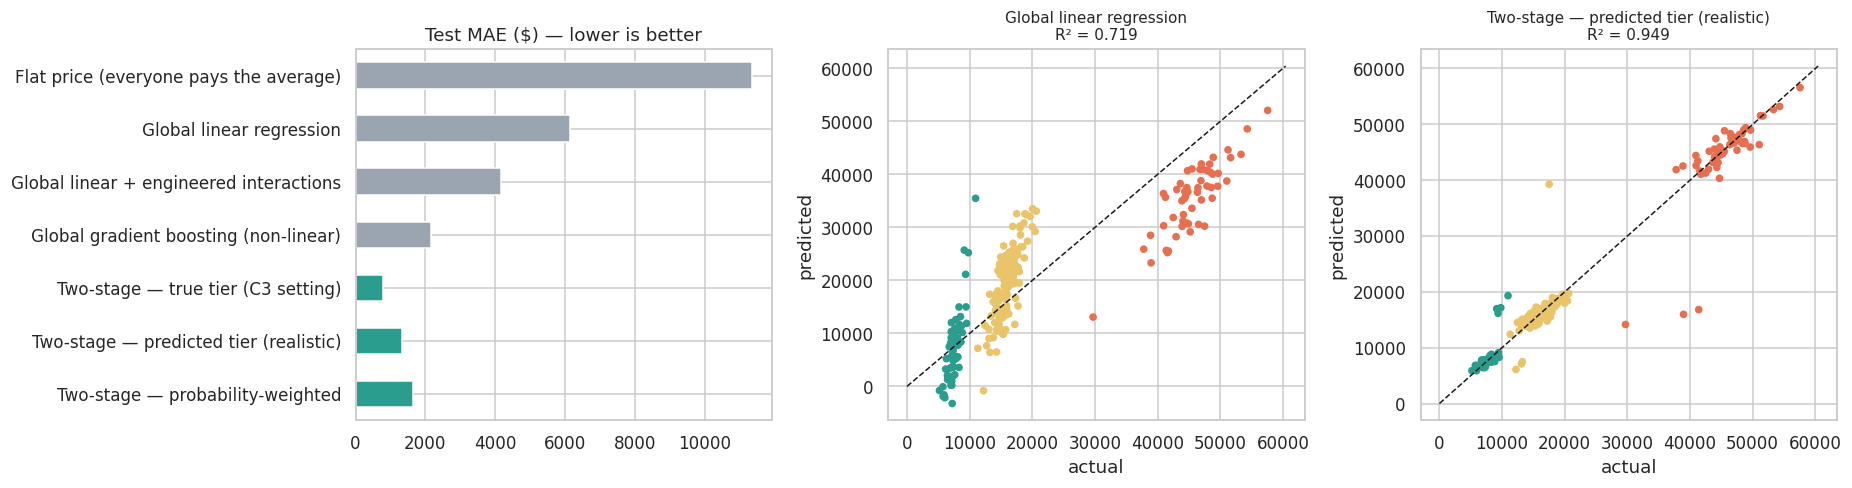

In [35]:
Xall, yall, tall = X_reg, y_reg, df_model['risk_tier']
Xtr_s, Xte_s, ytr_s, yte_s = Xall.loc[idx_tr], Xall.loc[idx_te], yall.loc[idx_tr], yall.loc[idx_te]

# one-size-fits-all challengers
glob = LinearRegression().fit(Xtr_s, ytr_s)
def global_plus(d):   # engineered flags + smoker interactions for a stronger single linear model
    g = add_features(d); g['smoker_x_bmi'] = g['smoker_yes'] * g['bmi']; g['smoker_x_age'] = g['smoker_yes'] * g['age']; return g
globp = LinearRegression().fit(global_plus(Xtr_s), ytr_s)
gbr = GradientBoostingRegressor(random_state=RANDOM_STATE).fit(Xtr_s, ytr_s)

# the two-stage engine trained on the same rows
regs_tr = {t: LinearRegression().fit(Xtr_s[tall.loc[idx_tr] == t], ytr_s[tall.loc[idx_tr] == t]) for t in TIERS}
def route(X, tiers):
    out = np.zeros(len(X)); tiers = np.asarray(tiers)
    for t in TIERS:
        if (tiers == t).any(): out[tiers == t] = regs_tr[t].predict(X[tiers == t])
    return out
tier_hat = clf.predict(Xte_s)                      # clf was trained on idx_tr only
proba = clf.predict_proba(Xte_s)
weighted = sum(proba[:, k] * regs_tr[c].predict(Xte_s) for k, c in enumerate(clf.classes_))

preds = {'Flat price (everyone pays the average)': np.full(len(yte_s), ytr_s.mean()),
         'Global linear regression': glob.predict(Xte_s),
         'Global linear + engineered interactions': globp.predict(global_plus(Xte_s)),
         'Global gradient boosting (non-linear)': gbr.predict(Xte_s),
         'Two-stage — true tier (C3 setting)': route(Xte_s, tall.loc[idx_te]),
         'Two-stage — predicted tier (realistic)': route(Xte_s, tier_hat),
         'Two-stage — probability-weighted': weighted}
cmp = pd.DataFrame({k: {'MAE': mean_absolute_error(yte_s, v), 'RMSE': rmse(yte_s, v), 'R²': r2_score(yte_s, v)}
                    for k, v in preds.items()}).T
display(cmp.round({'MAE': 0, 'RMSE': 0, 'R²': 3}))
print(f"Stage-1 accuracy on these test rows: {accuracy_score(tall.loc[idx_te], tier_hat):.3f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
cmp['MAE'].iloc[::-1].plot.barh(ax=ax[0], color=['#2a9d8f'] * 3 + ['#9aa5b1'] * 4); ax[0].set_title('Test MAE ($) — lower is better')
for a, key in zip(ax[1:], ['Global linear regression', 'Two-stage — predicted tier (realistic)']):
    a.scatter(yte_s, preds[key], c=tall.loc[idx_te].map(TIER_COLORS), s=16)
    lim = [0, yte_s.max() * 1.05]; a.plot(lim, lim, 'k--', lw=1)
    a.set_title(f"{key}\nR² = {r2_score(yte_s, preds[key]):.3f}", fontsize=10); a.set_xlabel('actual'); a.set_ylabel('predicted')
plt.tight_layout(); plt.show()

### ✍️ Reflection C3

1. | Model | MAE | R² |
   |---|---|---|
   | Global (C1) | **$5,680** | **0.695** |
   | Two-stage per-tier (C3) | **$881** | **0.993** |
   | *Two-stage realistic (predicted tiers, same test rows)* | *$1,316* | *0.949* |
   | *Global on those same rows* | *$6,142* | *0.719* |
2. **Yes — decisively.** MAE falls from $5,680 to $881, an **84% reduction ($4,799 less error per customer)**. The template's C3 uses each customer's *true* tier, which is optimistic, so I also ran the engine the way it will really work — the tree chooses the tier — on the same test customers as a global model: **MAE $1,316 vs $6,142 (−79%)**, R² 0.949 vs 0.719. It even beats stronger one-size-fits-all models: a global regression with engineered interactions ($4,166) and gradient boosting ($2,155).
3. By R², **Low fits best (0.806)** and **High worst (0.772)**; in dollars the gap is bigger — MAE **$369 for Low vs $1,845 for High**. Low-risk customers are very predictable; High-risk customers have larger, more varied charges and there are fewer of them (268) to learn from, so they carry the most pricing uncertainty. Why the combined R² (0.993) is higher than any single tier's: most of the variation in charges is **between** tiers. Once the tier is known, what is left to explain is small.

## Task C4 — Ridge & Lasso + Fine-Tuning (per tier)

In [36]:
alphas = [0.01, 0.1, 1, 10, 50, 100, 200]
c4_coefs, c4_sweeps, c4_best = {}, {}, {}
for tier in ['High', 'Medium', 'Low']:
    d = df_model[df_model['risk_tier'] == tier].drop(columns=['risk_tier'])
    Xd, yd = d.drop(columns=['annual_charge']), d['annual_charge']
    Xtr_t, Xte_t, ytr_t, yte_t = train_test_split(Xd, yd, test_size=0.2, random_state=RANDOM_STATE)
    scaler = StandardScaler().fit(Xtr_t); Xtr_ts, Xte_ts = scaler.transform(Xtr_t), scaler.transform(Xte_t)
    rows = []
    for a in alphas:
        r = Ridge(alpha=a).fit(Xtr_ts, ytr_t); l = Lasso(alpha=a, max_iter=10000).fit(Xtr_ts, ytr_t)
        rows.append({'alpha': a, 'Ridge R²': r2_score(yte_t, r.predict(Xte_ts)), 'Lasso R²': r2_score(yte_t, l.predict(Xte_ts)),
                     'Lasso non-zero coefs': int((np.abs(l.coef_) > 1e-6).sum())})
    sweep = pd.DataFrame(rows).set_index('alpha'); c4_sweeps[tier] = sweep
    # choose alpha by 5-fold CV on the TRAINING rows (the test set stays untouched)
    rcv = RidgeCV(alphas=np.logspace(-2, 3, 60)).fit(Xtr_ts, ytr_t)
    lcv = LassoCV(alphas=np.logspace(-1, 3, 60), cv=5, max_iter=50000, random_state=RANDOM_STATE).fit(Xtr_ts, ytr_t)
    ols = LinearRegression().fit(Xtr_ts, ytr_t)
    c4_best[tier] = {'OLS R²': r2_score(yte_t, ols.predict(Xte_ts)),
                     'Ridge α (CV)': rcv.alpha_, 'Ridge R²': r2_score(yte_t, rcv.predict(Xte_ts)),
                     'Lasso α (CV)': lcv.alpha_, 'Lasso R²': r2_score(yte_t, lcv.predict(Xte_ts))}
    c4_coefs[tier] = pd.Series(lcv.coef_, index=Xd.columns)
    print(f"\n=== {tier} tier — alpha sweep (template) ==="); print(sweep.round(3))
display(pd.DataFrame(c4_best).T.round(3))
coef_tbl = pd.DataFrame(c4_coefs)[['Low', 'Medium', 'High']]
print("Lasso coefficients (CV-tuned, standardised → $ change per 1 std-dev of the feature):")
display(coef_tbl.reindex(coef_tbl['High'].abs().sort_values(ascending=False).index).round(1))


=== High tier — alpha sweep (template) ===
        Ridge R²  Lasso R²  Lasso non-zero coefs
alpha                                           
0.01       0.772     0.772                     9
0.10       0.772     0.772                     9
1.00       0.773     0.772                     9
10.00      0.768     0.773                     9
50.00      0.691     0.775                     7
100.00     0.597     0.776                     6
200.00     0.472     0.767                     5

=== Medium tier — alpha sweep (template) ===
        Ridge R²  Lasso R²  Lasso non-zero coefs
alpha                                           
0.01       0.782     0.782                     9
0.10       0.782     0.782                     9
1.00       0.781     0.782                     9
10.00      0.775     0.779                     6
50.00      0.736     0.766                     5
100.00     0.681     0.740                     5
200.00     0.584     0.659                     4

=== Low tier — alpha sweep 

,OLS R²,Ridge α (CV),Ridge R²,Lasso α (CV),Lasso R²
High,0.772,0.732,0.773,51.507,0.776
Medium,0.782,0.602,0.782,17.270,0.777
Low,0.806,2.868,0.805,20.188,0.803


Lasso coefficients (CV-tuned, standardised → $ change per 1 std-dev of the feature):


,Low,Medium,High
bmi,266.5,950.7,3740.4
smoker_yes,340.3,1745.2,3133.0
age,525.8,1128.6,2207.6
children,340.1,423.4,669.8
sex_male,167.6,150.9,396.6
region_south,0.0,0.0,-84.0
region_north,-0.0,-0.0,-43.8
exercise_freq,0.0,-0.0,-0.0
region_west,0.0,18.8,0.0


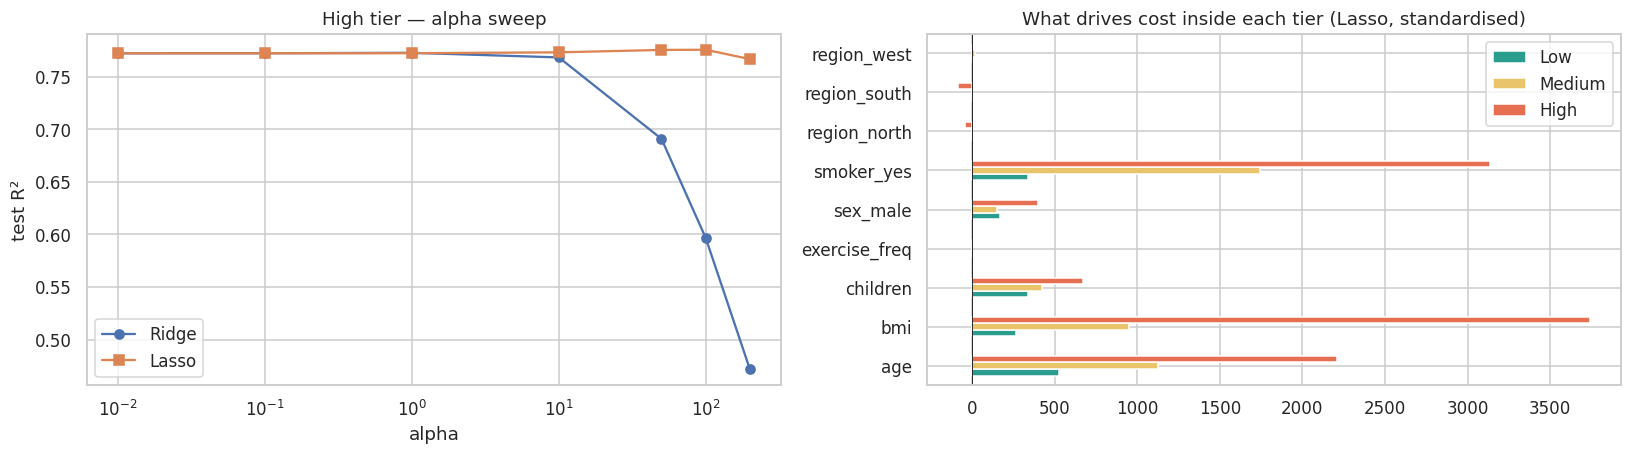

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
sw = c4_sweeps['High']
ax[0].plot(sw.index, sw['Ridge R²'], 'o-', label='Ridge'); ax[0].plot(sw.index, sw['Lasso R²'], 's-', label='Lasso')
ax[0].set_xscale('log'); ax[0].set_xlabel('alpha'); ax[0].set_ylabel('test R²'); ax[0].set_title('High tier — alpha sweep'); ax[0].legend()
coef_tbl.plot.barh(ax=ax[1], color=[TIER_COLORS[t] for t in coef_tbl.columns])
ax[1].axvline(0, c='k', lw=.6); ax[1].set_title('What drives cost inside each tier (Lasso, standardised)')
plt.tight_layout(); plt.show()

### ✍️ Reflection C4

1. **High tier sweep:** Ridge peaks at α ≈ 1 (R² 0.773); Lasso peaks at α ≈ 100 (0.776). In Medium and Low the best α is small (≈0.01–1, R² 0.782 and 0.806). Choosing α properly by 5-fold CV on the training rows gives Ridge α = 0.73 / 0.60 / 2.87 and Lasso α = 51.5 / 17.3 / 20.2 (High/Medium/Low), all within ±0.005 R² of plain OLS. When α gets **too large**, the penalty shrinks the *real* effects too: Ridge's High-tier R² collapses to **0.472 at α = 200**, and Lasso starts zeroing genuine drivers (only 4–5 left; Medium drops to 0.659) — the model becomes too simple (high bias / underfitting).
2. **High-tier drivers** (Lasso, $ per 1 standard deviation): **BMI +$3,740**, **smoker +$3,133**, **age +$2,208**, then children +$670 and male +$397. **Region barely matters** (south −$84, north −$44, west 0) and `exercise_freq` is **zero in every tier**. The ranking shifts by tier: Medium is led by smoking (+$1,745), then age and BMI; Low by age (+$526), then children and smoking.
3. Even after removing obvious junk, regularisation (a) stabilises coefficients when features overlap (exercise vs BMI), (b) protects small segments — the High tier has only ~214 training rows — from fitting noise, (c) gives an automatic, second opinion on which features deserve credit (confirming exercise and region add nothing), and (d) stays safe as new features are added later. Here the data is clean, so the accuracy gain is tiny; its value is robustness and interpretation.

## Task C5 — The Verdict

In [38]:
ladder = pd.DataFrame({t: {'Simple linear (1 feature)': c2.loc[t, 'simple R²'], 'Multiple linear (all features)': c2.loc[t, 'multiple R²'],
                           'Ridge (tuned)': c4_best[t]['Ridge R²'], 'Lasso (tuned)': c4_best[t]['Lasso R²']} for t in ['High', 'Medium', 'Low']})
ladder['average'] = ladder.mean(axis=1)
display(ladder.round(3))

gains = pd.Series({
    'Removing junk columns (A8, OLS test R² change)': r2_clean - r2_all,
    'Adding features (C2, simple → multiple, avg jump)': c2['jump'].mean(),
    'Splitting into tiers (global → two-stage realistic, R² change)': cmp.loc['Two-stage — predicted tier (realistic)', 'R²'] - cmp.loc['Global linear regression', 'R²'],
    'Tuning alpha (C4, best of Ridge/Lasso − OLS, avg)': np.mean([max(v['Ridge R²'], v['Lasso R²']) - v['OLS R²'] for v in c4_best.values()]),
})
display(gains.round(3).to_frame('gain in R²'))

,High,Medium,Low,average
Simple linear (1 feature),0.154,0.357,0.407,0.306
Multiple linear (all features),0.772,0.782,0.806,0.787
Ridge (tuned),0.773,0.782,0.805,0.786
Lasso (tuned),0.776,0.777,0.803,0.785


,gain in R²
"Removing junk columns (A8, OLS test R² change)",0.011
"Adding features (C2, simple → multiple, avg jump)",0.481
"Splitting into tiers (global → two-stage realistic, R² change)",0.229
"Tuning alpha (C4, best of Ridge/Lasso − OLS, avg)",0.001


### ✍️ Reflection C5

1. | Model | High R² | Avg across tiers | What it tells you |
   |---|---|---|---|
   | Simple linear (1 feature) | 0.154 | 0.306 | one driver explains little — cost is multi-factor |
   | Multiple linear (all features) | 0.772 | 0.787 | the kept features together explain ~79% within a tier |
   | Ridge (tuned) | 0.773 | 0.786 | shrinkage changes almost nothing → no overfitting to fix |
   | Lasso (tuned) | 0.776 | 0.785 | same accuracy with fewer features (exercise, region dropped) |
2. Measured gains in R²: **removing junk +0.011**, **adding features inside a tier +0.481**, **splitting into tiers +0.229** (global 0.719 → realistic two-stage 0.949; +0.275 with true tiers), **tuning α +0.001**. The biggest *structural* win over the real alternative (one global model) is **splitting into tiers**; the big "adding features" jump is measured from a deliberately weak one-feature starting point. What it reveals: this is a **segmentation problem**, not a regularisation problem — different customer groups follow different cost equations, and once you model each group separately a simple linear regression is enough. Tuning alpha adds nothing because the cleaned data has no noise features left to control.

# ⭐ Extension 1 — Customer Segmentation with Clustering

Clustering ignores the tier labels and asks: *do customers form natural groups on their own?* I cluster on the four risk-relevant features (age, BMI, exercise, smoker) after standardising them, so no feature dominates just because of its units.

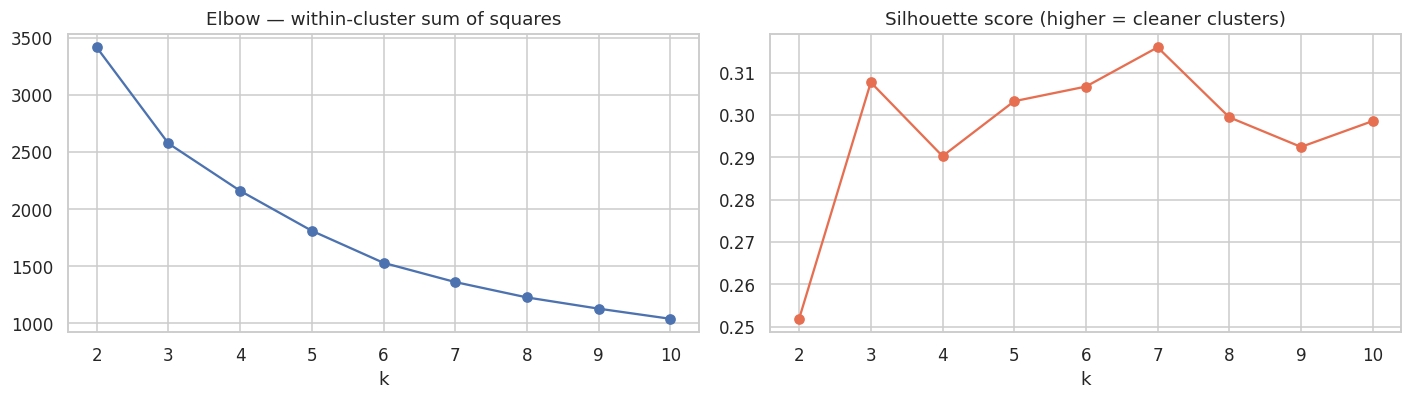

{2: 0.252, 3: 0.308, 4: 0.29, 5: 0.303, 6: 0.307, 7: 0.316, 8: 0.299, 9: 0.292, 10: 0.299}


In [39]:
clu_feats = ['age', 'bmi', 'exercise_freq', 'smoker_yes']
Zs = StandardScaler().fit_transform(df_model[clu_feats])
ks = range(2, 11); inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Zs)
    inertia.append(km.inertia_); sil.append(silhouette_score(Zs, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(ks, inertia, 'o-'); ax[0].set_title('Elbow — within-cluster sum of squares'); ax[0].set_xlabel('k')
ax[1].plot(ks, sil, 'o-', color='#e76f51'); ax[1].set_title('Silhouette score (higher = cleaner clusters)'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()
print({k: round(s, 3) for k, s in zip(ks, sil)})

In [40]:
best_sil = max(sil)
K = int([k for k, s_ in zip(ks, sil) if s_ >= best_sil - 0.01][0])   # simplest k within 0.01 of the best silhouette
print(f"Best silhouette {best_sil:.3f} at k={list(ks)[int(np.argmax(sil))]}; the curve is almost flat, so I take the simplest k within 0.01 of it → k = {K}")
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Zs)
clusters = pd.Series(km.labels_, index=df_model.index, name='cluster')
profile = df.assign(cluster=clusters).groupby('cluster').agg(
    customers=('age', 'size'), avg_age=('age', 'mean'), avg_bmi=('bmi', 'mean'), avg_exercise=('exercise_freq', 'mean'),
    smoker_share=('smoker', lambda s: (s == 'yes').mean()), avg_charge=('annual_charge', 'mean'))
AGE0 = df['age'].mean()
def name_cluster(r):   # describe each cluster relative to the whole customer base
    parts = ['older' if r['avg_age'] >= AGE0 + 5 else 'younger' if r['avg_age'] <= AGE0 - 5 else '',
             'heavier' if r['avg_bmi'] >= 30 else 'lean' if r['avg_bmi'] < 25 else '',
             'active' if r['avg_exercise'] >= 4.5 else '',
             'smokers' if r['smoker_share'] > 0.5 else 'non-smokers']
    txt = ' '.join(p for p in parts if p); return txt[0].upper() + txt[1:]
names = profile.apply(name_cluster, axis=1)
profile['segment name'] = [f"{n} #{i}" if (names == n).sum() > 1 else n for i, n in names.items()]
display(profile.round(2))
mix = pd.crosstab(clusters.map(profile['segment name']), df_model['risk_tier'], normalize='index')[TIERS]
display(mix.round(2))
print(f"Adjusted Rand Index (clusters vs risk tiers): {adjusted_rand_score(df_model['risk_tier'], clusters):.3f}  (1 = identical, 0 = random)")

Best silhouette 0.316 at k=7; the curve is almost flat, so I take the simplest k within 0.01 of it → k = 3


,customers,avg_age,avg_bmi,avg_exercise,smoker_share,avg_charge,segment name
cluster,,,,,,,
0,437,41.26,32.35,3.07,0.01,17973.88,Heavier non-smokers
1,416,41.07,22.90,5.01,0.03,11532.54,Lean active non-smokers
2,347,41.05,28.24,3.95,1.00,34610.23,Smokers


risk_tier,Low,Medium,High
cluster,,,
Heavier non-smokers,0.18,0.69,0.13
Lean active non-smokers,0.54,0.44,0.02
Smokers,0.01,0.40,0.58


Adjusted Rand Index (clusters vs risk tiers): 0.170  (1 = identical, 0 = random)


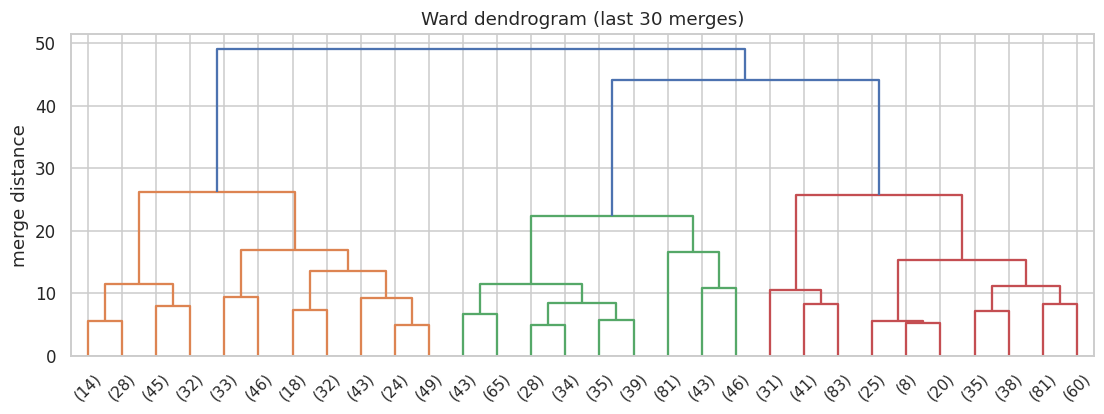

Agreement K-Means vs Ward (ARI): 0.794 | Ward vs tiers (ARI): 0.157


In [41]:
# Hierarchical clustering (Ward) as a second opinion
Zl = linkage(Zs, method='ward')
plt.figure(figsize=(12, 3.8)); dendrogram(Zl, truncate_mode='lastp', p=30, color_threshold=Zl[-(K - 1), 2])
plt.title('Ward dendrogram (last 30 merges)'); plt.ylabel('merge distance'); plt.show()
ward = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(Zs)
print(f"Agreement K-Means vs Ward (ARI): {adjusted_rand_score(clusters, ward):.3f} | Ward vs tiers (ARI): {adjusted_rand_score(df_model['risk_tier'], ward):.3f}")

### ✍️ Reflection — Clustering

- The silhouette curve is **flat (0.25–0.32 for k = 2–10)**, which means customers do **not** fall into sharply separated natural groups. I used the simplest k within 0.01 of the best score: **k = 3**.
- The three clusters split on **smoking** and on **BMI/exercise** (which move together, r = −0.78), not on age — all three average ~41 years: **heavier non-smokers** (BMI ~32, 69% Medium), **lean active non-smokers** (BMI ~23, 5 workouts/week, 54% Low) and **smokers** (58% High).
- **ARI vs risk tiers = 0.17** — the clusters are *not* the tiers. That makes sense: tiers depend on age thresholds combined with smoking and obesity, while K-Means looks for compact blobs in the overall feature space. Hierarchical (Ward) clustering finds similar groups (ARI 0.79 with K-Means), so the structure is stable.
- **Business use:** clustering is not a pricing tool here, but it is useful for **marketing personas and wellness targeting** — e.g. a weight-management offer for "heavier non-smokers" and a cessation programme for "smokers" (the two segments where behaviour change moves the premium the most).

# ⭐ Extension 2 — Dimensionality Reduction (PCA & LDA)

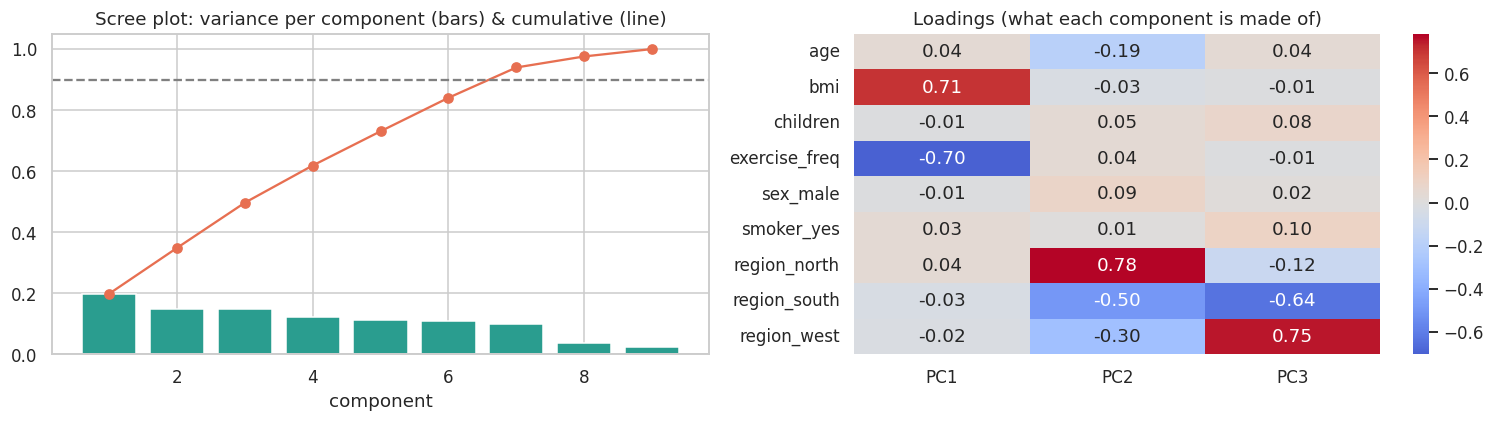

Variance explained: [0.198, 0.15, 0.148, 0.122, 0.112, 0.11, 0.099, 0.036, 0.024]
Top PC1 loadings: {'bmi': 0.71, 'exercise_freq': 0.7, 'region_north': 0.04}
corr(exercise_freq, bmi) = -0.78  ← why they load together
Components needed for 90% of the variance: 7 of 9


In [42]:
Zp_scaler = StandardScaler().fit(X_cls)
Zp = Zp_scaler.transform(X_cls)
pca = PCA(random_state=RANDOM_STATE).fit(Zp)
evr = pca.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(range(1, len(evr) + 1), evr, color='#2a9d8f'); ax[0].plot(range(1, len(evr) + 1), np.cumsum(evr), 'o-', color='#e76f51')
ax[0].axhline(0.9, ls='--', c='grey'); ax[0].set_title('Scree plot: variance per component (bars) & cumulative (line)'); ax[0].set_xlabel('component')
load = pd.DataFrame(pca.components_[:3].T, index=X_cls.columns, columns=['PC1', 'PC2', 'PC3'])
sns.heatmap(load, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[1]); ax[1].set_title('Loadings (what each component is made of)')
plt.tight_layout(); plt.show()
print("Variance explained:", np.round(evr, 3).tolist())
print("Top PC1 loadings:", load['PC1'].abs().sort_values(ascending=False).head(3).round(2).to_dict())
print(f"corr(exercise_freq, bmi) = {df['exercise_freq'].corr(df['bmi']):.2f}  ← why they load together")
print(f"Components needed for 90% of the variance: {int(np.argmax(np.cumsum(evr) >= 0.9) + 1)} of {len(evr)}")

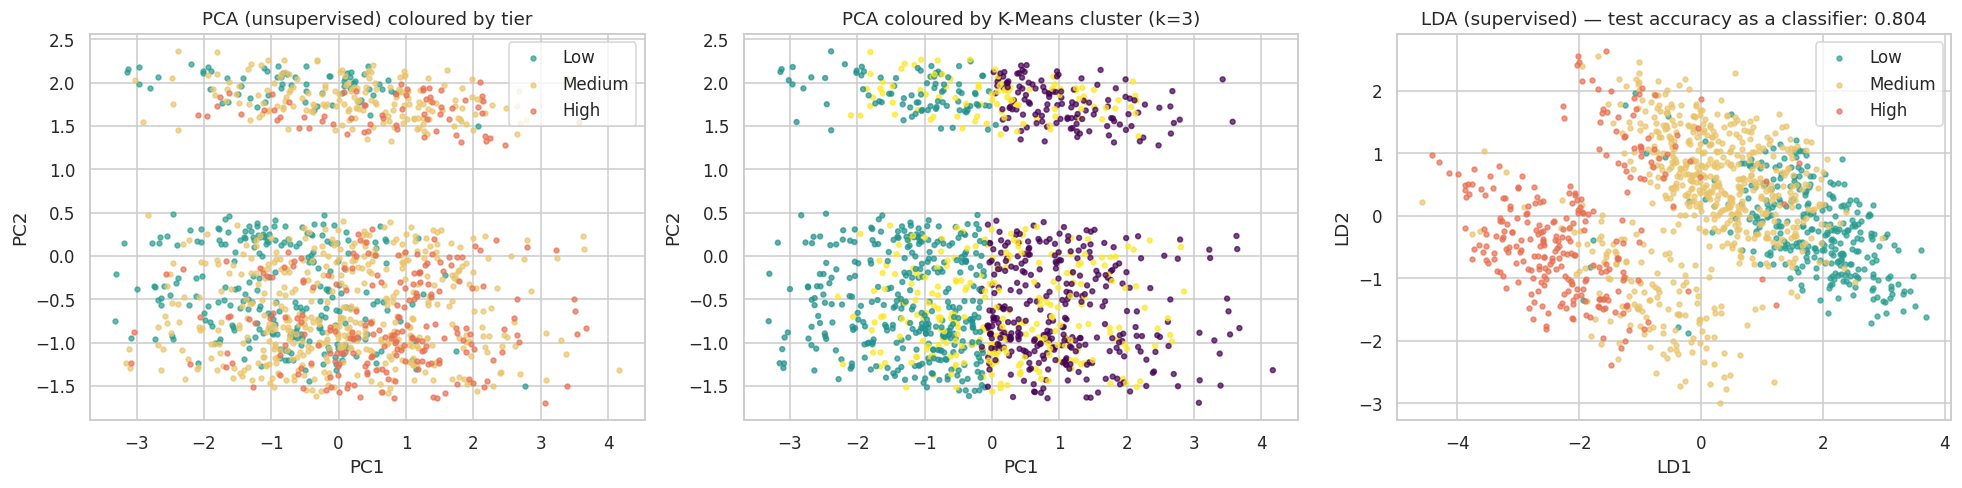

LDA test accuracy: 0.804 | between-tier variance captured by LD1/LD2: [0.983, 0.017]


In [43]:
P2 = pca.transform(Zp)[:, :2]
lda = LinearDiscriminantAnalysis(n_components=2).fit(Zp_scaler.transform(Xtr), ytr)
L2 = lda.transform(Zp)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
for t in TIERS:
    m_ = df_model['risk_tier'] == t
    ax[0].scatter(P2[m_, 0], P2[m_, 1], s=10, c=TIER_COLORS[t], label=t, alpha=.7)
    ax[2].scatter(L2[m_, 0], L2[m_, 1], s=10, c=TIER_COLORS[t], label=t, alpha=.7)
ax[0].set_title('PCA (unsupervised) coloured by tier'); ax[0].legend()
sc_ = ax[1].scatter(P2[:, 0], P2[:, 1], s=10, c=clusters, cmap='viridis', alpha=.7); ax[1].set_title(f'PCA coloured by K-Means cluster (k={K})')
ax[2].set_title(f"LDA (supervised) — test accuracy as a classifier: {accuracy_score(yte, lda.predict(Zp_scaler.transform(Xte))):.3f}"); ax[2].legend()
for a in ax[:2]: a.set_xlabel('PC1'); a.set_ylabel('PC2')
ax[2].set_xlabel('LD1'); ax[2].set_ylabel('LD2')
plt.tight_layout(); plt.show()
print(f"LDA test accuracy: {accuracy_score(yte, lda.predict(Zp_scaler.transform(Xte))):.3f} | "
      f"between-tier variance captured by LD1/LD2: {np.round(lda.explained_variance_ratio_, 3).tolist()}")

In [44]:
# Does compressing with PCA help KNN? (5-fold CV on the training rows)
rows = []
for nc in range(1, X_cls.shape[1] + 1):
    pipe_ = Pipeline([('sc', StandardScaler()), ('pca', PCA(n_components=nc, random_state=RANDOM_STATE)), ('knn', KNeighborsClassifier(15))])
    rows.append({'components': nc, 'variance kept': np.cumsum(evr)[nc - 1], 'KNN CV acc': cross_val_score(pipe_, Xtr, ytr, cv=cv).mean()})
pca_knn = pd.DataFrame(rows).set_index('components'); display(pca_knn.round(3).T)

components,1,2,3,4,5,6,7,8,9
variance kept,0.198,0.348,0.497,0.619,0.731,0.840,0.940,0.976,1.000
KNN CV acc,0.474,0.540,0.551,0.594,0.595,0.693,0.761,0.756,0.755


### ✍️ Reflection — Dimensionality reduction

- **PCA finds little to compress:** variance is spread evenly (PC1 19.8%, PC2 15.0%, PC3 14.8% …) and **7 of 9 components** are needed to keep 90% of the information — because A6 already removed the redundant columns. PC1 is essentially a **fitness axis** (BMI and exercise loading ≈ 0.71 / 0.70 with opposite signs).
- **PCA is unsupervised** — it keeps *variance*, not *tier information*. The PCA scatter shows the three tiers heavily overlapping, and KNN on PCA components peaks at **0.761 CV accuracy (7 components)** — never better than KNN on the original features. Compression mixes the crucial smoker signal with noise from region and sex.
- **LDA is supervised** — it looks for directions that *separate the tiers*. LD1 alone captures **98.3%** of the between-tier separation and the LDA plot shows the tiers lined up in order. As a classifier LDA scores **0.804** (it draws straight boundaries, so it cannot match the tree's thresholds).
- Take-away: for *this* dataset, feature selection (VIF + Lasso) beats dimensionality reduction; PCA would earn its place with many correlated inputs (see Bonus 2).

# ⭐ Extension 3 — The Premium Formula

The engine produces an **expected annual charge** (the pure cost of claims). A real price also has to cover running costs and profit, and optionally a cushion for uncertainty. The full formula:

$$\boxed{\text{Quoted premium} = \hat{C}_{\text{tier}}(x)\times(1+e+m) \;+\; z\cdot\sigma_{\text{tier}}}$$

| Symbol | Meaning | Default |
|---|---|---|
| $\hat{C}_{\text{tier}}(x)$ | Stage-2 expected charge from the **tier's own** linear equation (below) | — |
| $e$ | expense loading (admin, claims handling) | 10% |
| $m$ | profit margin | 5% |
| $z$ | safety factor (0 = off) | 0 |
| $\sigma_{\text{tier}}$ | typical prediction error of that tier's model (cross-validated RMSE) | from data |

Tier comes from Stage 1 (the tree); the scorecard gives the same answer 93% of the time and is easy to explain to a customer.

In [45]:
# Final per-tier equations, trained on ALL customers of each tier (exactly what Part E deploys)
final_eq = {}
for t in TIERS:
    d = df_model[df_model['risk_tier'] == t]
    m_ = LinearRegression().fit(d[X_reg.columns], d['annual_charge'])
    final_eq[t] = pd.Series(np.r_[m_.intercept_, m_.coef_], index=['intercept'] + list(X_reg.columns))
eq_tbl = pd.DataFrame(final_eq)
display(eq_tbl.round(0))
nice = {'age': 'Age', 'bmi': 'BMI', 'children': 'Children', 'exercise_freq': 'Workouts/wk', 'sex_male': '[Male]',
        'smoker_yes': '[Smoker]', 'region_north': '[North]', 'region_south': '[South]', 'region_west': '[West]'}
for t in TIERS:
    s = final_eq[t]
    terms = ' '.join(f"{'+' if v >= 0 else '−'} {abs(v):,.0f}·{nice[k]}" for k, v in s.drop('intercept').items())
    display(Markdown(f"**Ĉ<sub>{t}</sub>** = {s['intercept']:,.0f} {terms}"))

,Low,Medium,High
intercept,2890.0,5400.0,7285.0
age,60.0,89.0,201.0
bmi,78.0,174.0,691.0
children,262.0,308.0,456.0
exercise_freq,31.0,16.0,24.0
sex_male,381.0,377.0,795.0
smoker_yes,2763.0,4272.0,8127.0
region_north,-39.0,57.0,-326.0
region_south,-2.0,67.0,-409.0
region_west,-21.0,113.0,-233.0


**Ĉ<sub>Low</sub>** = 2,890 + 60·Age + 78·BMI + 262·Children + 31·Workouts/wk + 381·[Male] + 2,763·[Smoker] − 39·[North] − 2·[South] − 21·[West]

**Ĉ<sub>Medium</sub>** = 5,400 + 89·Age + 174·BMI + 308·Children + 16·Workouts/wk + 377·[Male] + 4,272·[Smoker] + 57·[North] + 67·[South] + 113·[West]

**Ĉ<sub>High</sub>** = 7,285 + 201·Age + 691·BMI + 456·Children + 24·Workouts/wk + 795·[Male] + 8,127·[Smoker] − 326·[North] − 409·[South] − 233·[West]

,flat: premium ÷ cost,engine: premium ÷ cost
tier,,
Low,3.14,1.22
Medium,1.48,1.15
High,0.52,1.12


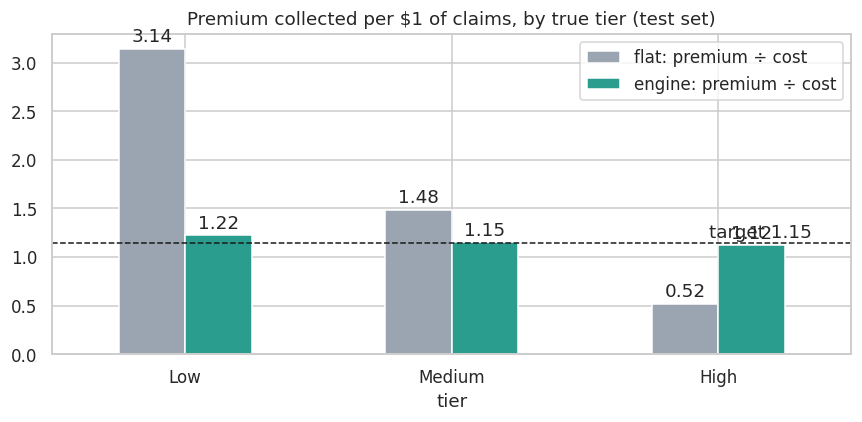

In [46]:
# Does it fix the flat-pricing problem? Price-to-cost ratio by tier on the unseen TEST customers
LOAD = 1 + 0.10 + 0.05
flat_prem = np.full(len(yte_s), ytr_s.mean() * LOAD)
engine_prem = preds['Two-stage — predicted tier (realistic)'] * LOAD
fair = pd.DataFrame({'actual charge': yte_s.values, 'tier': tall.loc[idx_te].values,
                     'flat premium': flat_prem, 'engine premium': engine_prem})
ratio = fair.groupby('tier')[['actual charge', 'flat premium', 'engine premium']].sum()
ratio = pd.DataFrame({'flat: premium ÷ cost': ratio['flat premium'] / ratio['actual charge'],
                      'engine: premium ÷ cost': ratio['engine premium'] / ratio['actual charge']}).reindex(TIERS)
display(ratio.round(2))
ax = ratio.plot.bar(figsize=(8, 4), color=['#9aa5b1', '#2a9d8f'], rot=0)
ax.axhline(LOAD, ls='--', c='k', lw=1); ax.text(2.35, LOAD + .05, 'target 1.15', ha='right')
ax.set_title('Premium collected per $1 of claims, by true tier (test set)')
for c in ax.containers: ax.bar_label(c, fmt='%.2f', padding=2)
plt.tight_layout(); plt.show()

### ✍️ Reflection — Premium formula

- **Reading the equations:** in the Low tier each extra BMI point costs **$78**, in the High tier **$691** — almost 9× more. Smoking adds **$2,763** in Low but **$8,127** in High; each child adds $262 → $456; men add $381 → $795. The *same* attribute costs more for a higher-risk customer — exactly why one global equation (C1) misprices both ends.
- **The biggest part of any premium is the tier itself** (the gap between the intercepts and slopes), which is why a single threshold crossing (e.g. BMI 29 → 31) can move a quote by thousands.
- **Fairness check vs flat pricing (unseen test customers, 15% loading):** the flat price collects **$3.14 per $1 of claims from Low-tier** customers, $1.48 from Medium, and only **$0.52 from High** — High-risk customers are subsidised by overcharged Low-risk ones, the exact problem in the brief. The engine collects **$1.22 / $1.15 / $1.12** — close to the 1.15 target in every tier, so the cross-subsidy disappears. High sits slightly below target because a few High customers are misrouted to Medium; the optional safety term z·σ (or the 15% loading) covers that.
- **Regions and exercise** have small coefficients that Lasso zeroed (C4); they are kept in the deployed equation for consistency with the template, but they should be read as "no reliable effect".

# PART D — Business Recommendation

### ✍️ Reflection D — The Board Memo

**To:** HealthWise Board  **From:** Data Science Team  **Re:** Smart Premium Engine — recommendation

**1. Does the engine beat flat pricing?** Yes. Pricing each customer with a risk tier and a tier-specific cost model cuts the average pricing error from **$5,680 to $881 (−84%)**, with R² rising from **0.695 to 0.993**. Even under a realistic test where the model must guess the tier itself, error drops **79% ($6,142 → $1,316)** and it beats every one-size-fits-all model we tried. Today's flat price collects **$3.14 per $1 of claims from low-risk customers but only $0.52 from high-risk ones**; the engine brings every tier close to our 15% target margin (1.12–1.22).

**2. What drives cost?** The top three drivers are **smoking** (smokers cost 2.4× more; +$2.8k to +$8.1k within a tier), **BMI** (obesity at BMI ≥ 30 pushes customers up a tier; each point costs up to $691 in the High tier) and **age** (thresholds at 45 and 58). Children and sex add smaller, steady amounts; region and exercise add nothing once these are known. **Worthless columns** we removed: favourite colour, zodiac sign, lucky number, preferred contact, marketing opt-in (plus duplicates weight and date of birth).

**3. Recommendation: deploy**, with a simple scorecard (2×smoker + BMI≥30 + age≥45 + age≥58) that agrees with the model for 99.8% of customers, so every tier decision can be explained in one sentence. **Risk to watch:** about 6% of customers belong to a tier our data cannot explain; the few high-risk customers misrouted to Medium are undercharged ~$21k each. Keep a small risk margin, add a medical questionnaire, and re-rate at renewal using actual claims.

# PART E — Deploy: the Interactive Premium Calculator ⭐

## Task E1 — Save the trained two-stage model

The engine code below is **identical** to the code inside `app.py`, so the notebook and the app always agree. Each model is a `Pipeline` (encoder + model), so one customer typed into the GUI is encoded exactly like the training data. Hyper-parameters come from the grid searches in Part B.

In [47]:
# ================= HealthWise two-stage engine (shared by notebook & app) =================
import numpy as np, pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

NUM = ['age', 'bmi', 'children', 'exercise_freq']      # kept numeric features
CAT = ['sex', 'smoker', 'region']                     # kept categorical features
FEATURES = NUM + CAT
ENG = ['obese', 'age_45plus', 'age_58plus', 'smoker_obese']   # engineered risk flags
TIERS = ['Low', 'Medium', 'High']
DEFAULT_PRICING = {'expense_load': 0.10, 'profit_margin': 0.05, 'safety_z': 0.0}


def clean_data(raw):
    """Drop duplicates, impute bmi from weight_kg (r≈0.99), exercise_freq with the median."""
    d = raw.drop_duplicates().reset_index(drop=True).copy()
    known = d['bmi'].notna()
    fit = LinearRegression().fit(d.loc[known, ['weight_kg']], d.loc[known, 'bmi'])
    if (~known).any():
        d.loc[~known, 'bmi'] = fit.predict(d.loc[~known, ['weight_kg']]).round(1)
    d['exercise_freq'] = d['exercise_freq'].fillna(d['exercise_freq'].median())
    return d, (float(fit.intercept_), float(fit.coef_[0]))


def _smoker01(d):
    if 'smoker_yes' in d.columns:
        return d['smoker_yes'].astype(int)
    return (d['smoker'].astype(str).str.strip().str.lower() == 'yes').astype(int)


def add_features(d):
    """Threshold flags suggested by the EDA (WHO obesity cut-off, age bands)."""
    d = d.copy()
    d['obese'] = (d['bmi'] >= 30).astype(int)
    d['age_45plus'] = (d['age'] >= 45).astype(int)
    d['age_58plus'] = (d['age'] >= 58).astype(int)
    d['smoker_obese'] = _smoker01(d) * d['obese']
    return d


def risk_points(d):
    """Transparent scorecard: 2×smoker + 1×(BMI≥30) + 1×(age≥45) + 1×(age≥58)."""
    return (2 * _smoker01(d) + (d['bmi'] >= 30).astype(int)
            + (d['age'] >= 45).astype(int) + (d['age'] >= 58).astype(int))


def scorecard_tier(points):
    points = np.asarray(points)
    return np.select([points == 0, points <= 2], ['Low', 'Medium'], 'High')


def make_pipe(model, num, scale=False):
    """Encoder + model in ONE object, so a single customer row is encoded exactly like training."""
    pre = ColumnTransformer([
        ('num', StandardScaler() if scale else 'passthrough', num),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), CAT)])
    return Pipeline([('pre', pre), ('model', model)])


def build_bundle(d, bmi_fit, hp, random_state=42):
    """Train Stage 1 (classifiers) + Stage 2 (one regressor per tier) on the cleaned data."""
    d = add_features(d)
    y_tier = d['risk_tier']
    classifiers = {
        'Decision Tree (Entropy)': {'model': make_pipe(DecisionTreeClassifier(
            criterion='entropy', random_state=random_state, **hp['dt_entropy']), NUM), 'features': FEATURES},
        'Decision Tree (Gini)': {'model': make_pipe(DecisionTreeClassifier(
            criterion='gini', random_state=random_state, **hp['dt_gini']), NUM), 'features': FEATURES},
        'KNN': {'model': make_pipe(KNeighborsClassifier(**hp['knn']), NUM + ENG, scale=True),
                'features': FEATURES + ENG},
        'Naive Bayes': {'model': make_pipe(GaussianNB(), NUM + ENG), 'features': FEATURES + ENG},
        'Logistic Regression': {'model': make_pipe(LogisticRegression(max_iter=5000, **hp['logreg']),
                                                   NUM + ENG, scale=True), 'features': FEATURES + ENG},
    }
    for c in classifiers.values():
        c['model'].fit(d[c['features']], y_tier)

    regs, sigma = {}, {}
    for t in TIERS:
        sub = d[d['risk_tier'] == t]
        regs[t] = make_pipe(LinearRegression(), NUM).fit(sub[FEATURES], sub['annual_charge'])
        cvp = cross_val_predict(make_pipe(LinearRegression(), NUM), sub[FEATURES], sub['annual_charge'],
                                cv=KFold(5, shuffle=True, random_state=random_state))
        sigma[t] = float(np.sqrt(np.mean((sub['annual_charge'] - cvp) ** 2)))

    return {
        'clf': classifiers['Decision Tree (Entropy)']['model'],      # Stage 1 (deployed)
        'regs': regs,                                                 # Stage 2 (one per tier)
        'classifiers': classifiers,                                   # all Stage-1 candidates
        'features': FEATURES, 'num': NUM, 'cat': CAT, 'eng': ENG, 'tiers': TIERS,
        'med': {c: float(d[c].median()) for c in NUM},
        'cat_mode': {c: str(d[c].mode()[0]) for c in CAT},
        'bmi_from_weight': bmi_fit, 'sigma': sigma, 'pricing': dict(DEFAULT_PRICING),
        'hyperparams': hp, 'flat_charge': float(d['annual_charge'].mean()),
        'ranges': {c: (float(d[c].min()), float(d[c].max())) for c in NUM},
    }


def prepare_row(customer, M):
    """One customer dict -> clean one-row DataFrame (fills blanks the same way as training)."""
    row = pd.DataFrame([dict(customer)])
    for c in M['cat']:
        v = row.at[0, c] if c in row.columns else None
        row[c] = M['cat_mode'][c] if v is None or pd.isna(v) or str(v).strip() == '' else str(v).strip().lower()
    for c in M['num']:
        v = row.at[0, c] if c in row.columns else None
        v = pd.to_numeric(v, errors='coerce')
        if pd.isna(v) and c == 'bmi' and 'weight_kg' in row.columns and pd.notna(pd.to_numeric(row.at[0, 'weight_kg'], errors='coerce')):
            a, b = M['bmi_from_weight']
            v = round(a + b * float(row.at[0, 'weight_kg']), 1)
        row[c] = M['med'][c] if pd.isna(v) else float(v)
    return add_features(row)


def predict_full(customer, M, expense_load=None, profit_margin=None, safety_z=None, weighted=False):
    """Stage 1 -> tier (+ probabilities); Stage 2 -> that tier's regressor; then the pricing formula."""
    row = prepare_row(customer, M)
    X = row[M['features']]
    clf = M['clf']
    tier = str(clf.predict(X)[0])
    proba = {str(t): float(p) for t, p in zip(clf.classes_, clf.predict_proba(X)[0])}
    by_tier = {t: float(M['regs'][t].predict(X)[0]) for t in M['tiers']}
    expected = by_tier[tier]
    weighted_charge = float(sum(proba.get(t, 0) * by_tier[t] for t in M['tiers']))
    p = dict(M['pricing'])
    for k, v in (('expense_load', expense_load), ('profit_margin', profit_margin), ('safety_z', safety_z)):
        if v is not None:
            p[k] = v
    base = weighted_charge if weighted else expected
    risk_margin = p['safety_z'] * M['sigma'][tier]
    quoted = base * (1 + p['expense_load'] + p['profit_margin']) + risk_margin
    return {'tier': tier, 'proba': proba, 'expected_charge': expected, 'weighted_charge': weighted_charge,
            'charge_by_tier': by_tier, 'quoted_premium': float(quoted), 'risk_margin': float(risk_margin),
            'pricing': p, 'risk_points': int(risk_points(row).iloc[0]),
            'scorecard_tier': str(scorecard_tier(risk_points(row))[0]), 'row': row}
# ===========================================================================================


hp = {'dt_entropy': best_params[('raw', 'Decision Tree (Entropy)')],
      'dt_gini':    best_params[('raw', 'Decision Tree (Gini)')],
      'knn':        {k.replace('m__', ''): v for k, v in best_params[('raw + engineered', 'KNN')].items()},
      'logreg':     {k.replace('m__', ''): v for k, v in best_params[('raw + engineered', 'Logistic Regression')].items()}}
df_clean, bmi_coef = clean_data(pd.read_csv('healthwise.csv'))          # same cleaning as Part A
M = build_bundle(df_clean, bmi_coef, hp, random_state=RANDOM_STATE)
joblib.dump(M, 'healthwise_model.joblib')
print("Saved healthwise_model.joblib  |  hyper-parameters:", hp)
print("Tier error bands σ (CV RMSE):", {t: round(v) for t, v in M['sigma'].items()})

# check: the saved Stage-2 pipelines reproduce the Extension-3 equations exactly
chk = df_clean.head(50)
for t in TIERS:
    manual = final_eq[t]['intercept'] + (df_model.loc[chk.index, X_reg.columns] * final_eq[t].drop('intercept')).sum(axis=1)
    assert np.allclose(manual.values, M['regs'][t].predict(chk[FEATURES])), t
print("✔ saved pipelines == printed premium formula")

Saved healthwise_model.joblib  |  hyper-parameters: {'dt_entropy': {'max_depth': 4, 'min_samples_leaf': 5}, 'dt_gini': {'max_depth': 4, 'min_samples_leaf': 5}, 'knn': {'n_neighbors': 7, 'weights': 'distance'}, 'logreg': {'C': 1}}
Tier error bands σ (CV RMSE): {'Low': 461, 'Medium': 892, 'High': 1970}
✔ saved pipelines == printed premium formula


### ✍️ Reflection E1

1. The regression learned one coefficient per **column, in a fixed order** (e.g. `smoker_yes` is column 6). If a single customer row is encoded with a fresh `get_dummies`, only the categories present in that row are created — a female non-smoker produces no `sex_male` or `smoker_yes` column at all — so columns go missing or shift position and the model silently multiplies the wrong numbers. The **fitted** `OneHotEncoder` always outputs the same columns in the same order (and handles unseen categories), and wrapping encoder + model in one `Pipeline` means they can never drift apart. *(Detail I fixed: the template re-uses one `pre` object in four pipelines; since a Pipeline doesn't copy it, all of them would end up sharing the last-fitted encoder. `make_pipe()` builds a fresh encoder for every model.)*
2. Because it is a **two-stage** engine: the classifier decides *which* cost equation applies, and each tier has genuinely different slopes (smoking +$2,763 in Low vs +$8,127 in High; BMI $78 vs $691 per point). One model would average those slopes and misprice both ends (C1). The file also stores what the app needs to treat new inputs exactly like training data: medians for blanks, the BMI-from-weight rule, each tier's error band σ, the pricing loadings and the other Stage-1 models for comparison.

## Task E2 — The prediction function and the GUI

In [48]:
M = joblib.load('healthwise_model.joblib')
clf_app, regs, FEATURES, NUM, med = M['clf'], M['regs'], M['features'], M['num'], M['med']

def predict(customer: dict):
    # Lab-compatible: returns (tier, premium) where premium = Stage-2 expected annual charge
    r = predict_full(customer, M)
    return r['tier'], round(r['expected_charge'], 2)

base = dict(age=30, sex='female', bmi=24.0, children=1, smoker='no', region='south', exercise_freq=5)
print("Baseline customer:", predict(base))

Baseline customer: ('Low', 6975.35)


In [49]:
# What-if table: change ONE thing at a time from a Low-risk customer
scenarios = {'baseline (low risk)': {}, 'smoker → yes': {'smoker': 'yes'}, 'children +2': {'children': 3},
             'age → 50': {'age': 50}, 'bmi → 32': {'bmi': 32.0}, 'exercise → 1/week': {'exercise_freq': 1},
             'smoker + bmi 32 + age 50': {'smoker': 'yes', 'bmi': 32.0, 'age': 50}}
rows = []
for name, change in scenarios.items():
    r = predict_full({**base, **change}, M)
    rows.append({'scenario': name, 'risk points': r['risk_points'], 'tier': r['tier'],
                 'P(Low/Med/High)': '/'.join(f"{r['proba'].get(t, 0):.2f}" for t in TIERS),
                 'expected charge': round(r['expected_charge']), 'quoted premium (+15%)': round(r['quoted_premium'])})
whatif = pd.DataFrame(rows).set_index('scenario')
whatif['Δ vs baseline'] = whatif['expected charge'] - whatif.loc['baseline (low risk)', 'expected charge']
display(whatif)

,risk points,tier,P(Low/Med/High),expected charge,quoted premium (+15%),Δ vs baseline
scenario,,,,,,
baseline (low risk),0,Low,0.95/0.05/0.00,6975,8022,0
smoker → yes,2,Medium,0.00/0.98/0.02,16977,19524,10002
children +2,0,Low,0.95/0.05/0.00,7499,8624,524
age → 50,1,Medium,0.04/0.92/0.04,14493,16667,7518
bmi → 32,1,Medium,0.01/0.97/0.03,14096,16210,7121
exercise → 1/week,0,Low,0.95/0.05/0.00,6849,7877,-126
smoker + bmi 32 + age 50,4,High,0.00/0.02/0.98,47752,54915,40777


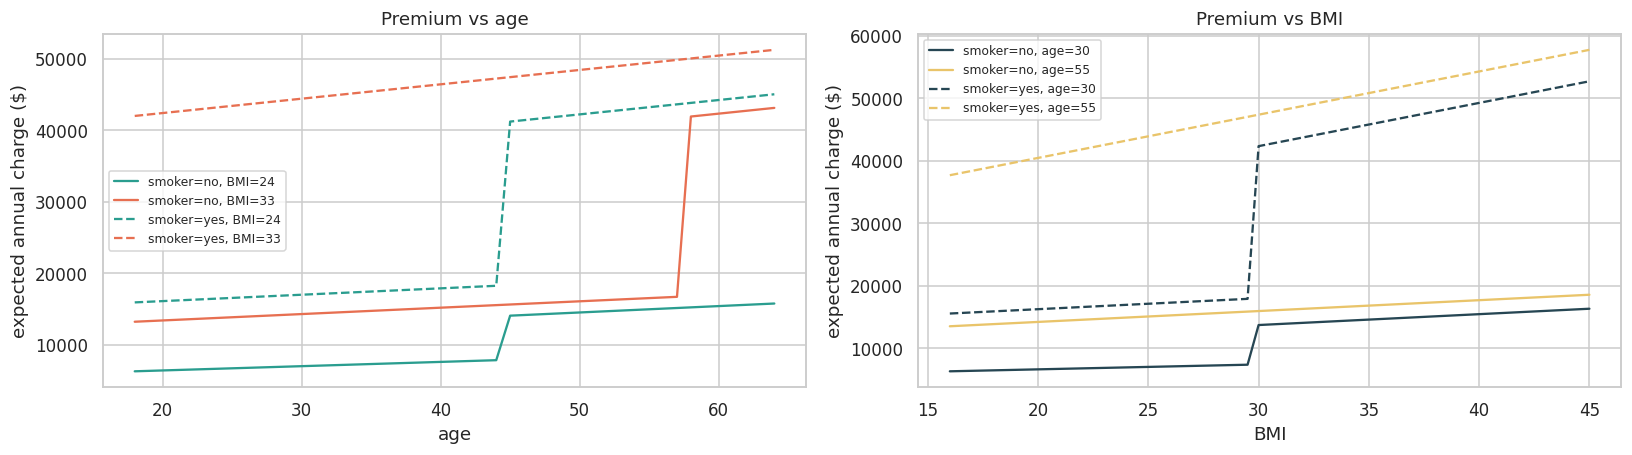

In [50]:
# Premium curves: watch the jumps where Stage 1 switches tier (and therefore switches regressor)
ages = np.arange(18, 65)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
for smk, ls in [('no', '-'), ('yes', '--')]:
    for b, col in [(24, '#2a9d8f'), (33, '#e76f51')]:
        ax[0].plot(ages, [predict_full({**base, 'age': a, 'bmi': b, 'smoker': smk}, M)['expected_charge'] for a in ages],
                   ls, color=col, label=f'smoker={smk}, BMI={b}')
bmis = np.arange(16, 45.5, .5)
for smk, ls in [('no', '-'), ('yes', '--')]:
    for a, col in [(30, '#264653'), (55, '#e9c46a')]:
        ax[1].plot(bmis, [predict_full({**base, 'bmi': b, 'age': a, 'smoker': smk}, M)['expected_charge'] for b in bmis],
                   ls, color=col, label=f'smoker={smk}, age={a}')
ax[0].set_xlabel('age'); ax[1].set_xlabel('BMI')
for a_ in ax: a_.set_ylabel('expected annual charge ($)'); a_.legend(fontsize=8)
ax[0].set_title('Premium vs age'); ax[1].set_title('Premium vs BMI'); plt.tight_layout(); plt.show()

### Option B — ipywidgets GUI (live inside Jupyter / Colab). Move any slider and the tier + premium recalculate instantly. *(Option A, the full Streamlit app with the dashboard, is in `app.py`.)*

In [51]:
import ipywidgets as widgets
style = {'description_width': '110px'}
w = dict(age=widgets.IntSlider(value=40, min=18, max=64, description='Age', style=style),
         bmi=widgets.FloatSlider(value=27, min=16, max=45, step=0.1, description='BMI', style=style),
         children=widgets.IntSlider(value=1, min=0, max=4, description='Children', style=style),
         exercise_freq=widgets.IntSlider(value=3, min=0, max=7, description='Workouts/week', style=style),
         sex=widgets.Dropdown(options=['male', 'female'], description='Sex', style=style),
         smoker=widgets.Dropdown(options=['no', 'yes'], description='Smoker', style=style),
         region=widgets.Dropdown(options=['north', 'south', 'east', 'west'], description='Region', style=style))
load_w = widgets.FloatSlider(value=0.15, min=0, max=0.5, step=0.01, description='Loadings e+m', style=style, readout_format='.0%')
out = widgets.Output()
def update(_=None):
    with out:
        out.clear_output()
        r = predict_full({k: x.value for k, x in w.items()}, M, expense_load=load_w.value, profit_margin=0.0)
        probs = '  '.join(f"{t}: {r['proba'].get(t, 0):.0%}" for t in TIERS)
        print(f"Risk points: {r['risk_points']}  →  Predicted tier: {r['tier']}   ({probs})")
        print(f"Expected annual charge (Stage 2): ${r['expected_charge']:,.0f}")
        print(f"Quoted premium incl. {load_w.value:.0%} loadings: ${r['quoted_premium']:,.0f}")
for x in list(w.values()) + [load_w]: x.observe(update, 'value')
display(widgets.VBox([widgets.HBox([widgets.VBox(list(w.values())[:4]), widgets.VBox(list(w.values())[4:] + [load_w])]), out]))
update()

### ✍️ Reflection E2

1. The what-if table and the ipywidgets panel above show live predictions (e.g. baseline customer → **Low, $6,975**). The Streamlit app (`app.py`) does the same with a full dashboard; screenshot it running for the submission.
2. Baseline: 30-year-old female, BMI 24, 1 child, non-smoker, 5 workouts/week → **0 risk points, Low tier, $6,975** (quote $8,022 with 15% loadings). Switching **smoker → yes**: risk points 0 → 2, the tree moves her to **Medium (98% probability)**, and the premium jumps to **$16,977 (+$10,002, 2.4×)**. Two things happen at once, which is the two-stage logic in action: **Stage 1** re-classifies her, so **Stage 2** switches from the Low equation (intercept $2,890) to the Medium equation (intercept $5,400, steeper slopes), *and* the Medium smoker coefficient (+$4,272) is added. Add BMI 32 and age 50 as well and she becomes **High at $47,752**.
3. From the same baseline: **smoker +$10,002 > age 30→50 +$7,518 > BMI 24→32 +$7,121** — each of these crosses a tier boundary here, so the tier jump is most of the change. Within a tier, smoking is the largest single switch in every tier (+$2.8k / $4.3k / $8.1k), consistent with C4, where smoking is a top-2 driver in all tiers. In the High tier, BMI has the largest *standardised* effect in C4 because BMI varies a lot (one standard deviation ≈ 5.5 points × $691 ≈ $3.8k). The premium curves show the jumps clearly at age 45 and 58 and at BMI 30. Exercise barely moves the price (−$126), matching Lasso's zero.

## Task E3 — Score the unseen customers ⭐

Put the instructor's file next to this notebook as `test_customers.csv` and re-run this cell. Until then it scores `unseen_customers_sample.csv` (six made-up customers, one with a missing BMI to prove the blank-handling works).

In [52]:
UNSEEN = 'test_customers.csv' if os.path.exists('test_customers.csv') else 'unseen_customers_sample.csv'
new = pd.read_csv(UNSEEN); print("Scoring:", UNSEEN, new.shape)
out_rows = []
for _, r in new.iterrows():
    res = predict_full(r.to_dict(), M)
    out_rows.append({'predicted_tier': res['tier'], 'risk_points': res['risk_points'],
                     'expected_charge': round(res['expected_charge']), 'quoted_premium': round(res['quoted_premium'])})
scored = pd.concat([new, pd.DataFrame(out_rows)], axis=1); display(scored)
scored.to_csv('unseen_customers_scored.csv', index=False)

# Instructor-style adjustments (edit these to whatever your instructor names)
changes = [(0, 'smoker → yes', {'smoker': 'yes'}), (1, 'children +2', 'children+2'), (5, 'age +15', 'age+15'), (3, 'bmi → 24', {'bmi': 24.0})]
rows = []
for i, label, ch in changes:
    cust = new.iloc[i].to_dict()
    if isinstance(ch, str):
        col, inc = ch.split('+'); ch = {col: cust[col] + int(inc)}
    before, after = predict_full(cust, M), predict_full({**cust, **ch}, M)
    rows.append({'customer': cust.get('customer_id', i + 1), 'tier': before['tier'], 'premium': round(before['expected_charge']),
                 'change applied': label, 'new tier': after['tier'], 'updated premium': round(after['expected_charge']),
                 'Δ premium': round(after['expected_charge'] - before['expected_charge'])})
display(pd.DataFrame(rows))

Scoring: unseen_customers_sample.csv (6, 9)


,customer_id,age,sex,bmi,weight_kg,children,smoker,region,exercise_freq,predicted_tier,risk_points,expected_charge,quoted_premium
0,NEW01,25,female,22.0,63.5,0,no,south,5,Low,0,6258,7197
1,NEW02,38,male,31.5,92.0,2,no,north,3,Medium,1,15367,17672
2,NEW03,52,male,27.0,78.0,1,yes,east,2,High,3,45831,52706
3,NEW04,61,female,33.0,96.0,3,no,west,4,High,3,43591,50130
4,NEW05,33,female,NaN,95.0,1,yes,north,4,High,3,44945,51686
5,NEW06,47,male,24.0,70.0,4,no,south,6,Medium,1,15541,17872


,customer,tier,premium,change applied,new tier,updated premium,Δ premium
0,NEW01,Low,6258,smoker → yes,Medium,15875,9616
1,NEW02,Medium,15367,children +2,Medium,15983,616
2,NEW06,Medium,15541,age +15,Medium,16882,1341
3,NEW04,High,43591,bmi → 24,Medium,16124,-27468


### ✍️ Reflection E3

*(Filled with the sample file — re-run with the instructor's `test_customers.csv` and update the numbers.)*

| Customer | Predicted tier | Premium | Change applied | Updated premium |
|---|---|---|---|---|
| NEW01 | Low | $6,258 | smoker → yes (→ Medium) | $15,875 |
| NEW02 | Medium | $15,367 | children +2 | $15,983 |
| NEW06 | Medium | $15,541 | age +15 | $16,882 |
| NEW04 | High | $43,591 | BMI 33 → 24 (→ Medium) | $16,124 |

1. **Reasonable:** the young healthy customer (NEW01) is Low; the 52-year-old smoker (NEW03) is High at $45,831; the 61-year-old obese non-smoker (NEW04) is High through two age points plus obesity. NEW05 had **no BMI**, so the app estimated it from 95 kg (≈ 32.8), which made her an obese smoker → High — the blank-handling works. The one mild surprise: NEW06, a 47-year-old non-smoker with BMI 24, stays Medium even at age 62 — without smoking or obesity, age alone only adds points gradually.
2. **Yes, in direction and size.** Two extra children add **$616** — exactly 2 × the Medium-tier child coefficient ($308), no tier change: a small, linear, predictable cost. Making NEW01 a smoker adds **$9,616** because she jumps a tier. Reducing NEW04's BMI to 24 cuts **$27,468** because it drops her from High to Medium. For the business: smoking and obesity are **threshold risks with large jumps**, children and age are gradual — so smoking-cessation and weight-management programmes have the biggest, most measurable effect on claims and premiums.

# ⭐ Bonus Tasks

## Bonus 1 — Error propagation

In [53]:
err = pd.DataFrame({'true': tall.loc[idx_te].values, 'pred': tier_hat, 'actual': yte_s.values,
                    'hard': preds['Two-stage — predicted tier (realistic)'], 'weighted': weighted,
                    'max_p': proba.max(axis=1)})
err['error'] = err['hard'] - err['actual']
tab = err.groupby(['true', 'pred'])['error'].agg(['count', 'mean']).round(0)
display(tab.rename(columns={'mean': 'avg pricing error ($, − = undercharged)'}))

def underpriced_high(p): m_ = err['true'] == 'High'; return float(np.clip(err.loc[m_, 'actual'] - p[m_], 0, None).sum())
safe = np.maximum(err['hard'], err['weighted'])            # never price below the probability-weighted cost
refer = err['max_p'] < 0.80
print(f"Undercharge on truly-High customers (test set): hard routing ${underpriced_high(err['hard']):,.0f} | "
      f"probability-weighted ${underpriced_high(err['weighted']):,.0f} | max(hard, weighted) ${underpriced_high(safe):,.0f}")
print(f"MAE: hard {mean_absolute_error(err['actual'], err['hard']):,.0f} | max(hard, weighted) {mean_absolute_error(err['actual'], safe):,.0f}")
print(f"Customers the tree is unsure about (max probability < 80%): {refer.sum()} of {len(err)} "
      f"→ Stage-1 accuracy on them {(err.loc[refer,'true'] == err.loc[refer,'pred']).mean():.0%} vs "
      f"{(err.loc[~refer,'true'] == err.loc[~refer,'pred']).mean():.0%} on the rest")

count  avg pricing error ($, − = undercharged)
true   pred                                                  
High   High       51                                     13.0
       Medium      3                                 -21033.0
Low    Low        57                                    -24.0
       Medium      4                                   7596.0
Medium High        1                                  21759.0
       Low         3                                  -5948.0
       Medium    121                                    -11.0

Undercharge on truly-High customers (test set): hard routing $96,581 | probability-weighted $158,773 | max(hard, weighted) $94,360
MAE: hard 1,316 | max(hard, weighted) 1,428
Customers the tree is unsure about (max probability < 80%): 1 of 240 → Stage-1 accuracy on them 100% vs 95% on the rest


In [54]:
# Root cause: check every customer against the scorecard rules (full data)
viol = df_model[scorecard_tier(risk_points(df_model)) != df_model['risk_tier']]
near = lambda d: ((d['bmi'] - 30).abs() <= 1) | ((d['age'] - 45).abs() <= 1) | ((d['age'] - 58).abs() <= 1)
print(f"Customers whose recorded tier contradicts the rules: {len(viol)} ({len(viol)/len(df_model):.1%})")
print(f"   within ±1 of a threshold: {near(viol).mean():.0%} of them vs {near(df_model).mean():.0%} of all customers → not a boundary problem")
print("   their charges follow the RECORDED tier:")
display(viol.assign(rule_tier=scorecard_tier(risk_points(viol))).groupby(['risk_tier', 'rule_tier'])['annual_charge']
        .agg(['count', 'mean']).round(0))
buffer = underpriced_high(err['hard']) / len(err)
print(f"Undercharge spread over every test customer: ${buffer:,.0f} each ≈ {buffer / yte_s.mean():.1%} of the average charge")

Customers whose recorded tier contradicts the rules: 73 (6.1%)
   within ±1 of a threshold: 27% of them vs 24% of all customers → not a boundary problem
   their charges follow the RECORDED tier:


count     mean
risk_tier rule_tier                
High      Medium        17  38050.0
Low       Medium        23   9188.0
Medium    High          14  19984.0
          Low           19  13493.0

Undercharge spread over every test customer: $402 each ≈ 2.0% of the average charge


### ✍️ Reflection — Bonus 1

- **What happens:** a truly High-risk customer routed to a lower tier is priced with the wrong equation. In the test set the 3 High → Medium cases were **undercharged by ~$21,000 each** (priced ~$16k by the Medium equation, actually costing ~$37k). Across the test set that is **$96,581**, or about **$402 per customer (≈2% of the average charge)** — a hidden subsidy paid by everyone else. A High → Low error would be worse still (~$38k each), but it never happened.
- **Why it happens:** 6.1% of customers have a recorded tier that **contradicts the rules**, they are **not** concentrated near the thresholds (27% within ±1 of BMI 30 / age 45 / 58, vs 24% of all customers), and their charges follow their *recorded* tier (rule-Medium but recorded-High customers average $38k). So the tier depends on information **not in this dataset** (medical history, previous claims). No classifier trained on these columns can catch them — which is also why the tree is confident even when wrong: only 1 of 240 test customers had a top probability below 80%, and **probability-weighted pricing actually made High undercharging worse** ($158,773).
- **Safeguards I would add:** (1) a short **medical questionnaire / underwriting review** to capture the missing information; (2) a **risk margin** — the formula's z·σ term or a pooled ~2% buffer (the 15% loading already absorbs it); (3) **re-rate at renewal** using actual claims (experience rating) so a misrouted customer is corrected after one year; (4) monitor the **loss ratio per tier** monthly and trigger a review if the High tier drifts below target.

## Bonus 2 — When would you use PCA?

### ✍️ Reflection — Bonus 2

I would use PCA when there are **many correlated inputs** — for example dozens of lab-test results, wearable-sensor streams or hundreds of diagnosis codes — where multicollinearity is severe, a model would overfit, or distance-based methods like KNN suffer from too many dimensions; it is also handy for visualising high-dimensional data in 2D. The trade-off is **interpretability**: each component is a blend of original columns, so I could no longer tell the board "each BMI point costs $691", and because PCA is unsupervised it keeps the directions with the most *variance*, not the most *predictive* ones. That is exactly what happened here: 7 of 9 components were needed for 90% of the variance and KNN on PCA components (best 0.761) never beat KNN on the original features, so VIF + Lasso was the right tool for this dataset (LDA is the supervised alternative when the goal is separating classes).

## 📦 Files produced

In [55]:
for f in ['healthwise_model.joblib', 'unseen_customers_scored.csv', 'app.py']:
    print(f"{f:32} {'✔ found' if os.path.exists(f) else '— (ships alongside this notebook)'}")
print("\nRun the GUI + dashboard with:   streamlit run app.py")

healthwise_model.joblib          ✔ found
unseen_customers_scored.csv      ✔ found
app.py                           ✔ found

Run the GUI + dashboard with:   streamlit run app.py
